# Two Markets, a Transfer, and Wheeling on the WSCC 9-Bus Network

> **Work in progress** — an illustrative teaching notebook under active development, not an authoritative reference.

Two markets share the grid. Market A is split across two balancing authorities that are
not electrically connected: BA-A1 at node 2 and BA-A2 at node 3. Market A's two
balancing authorities coordinate only through a **transfer**, a scheduled transfer with
released capacity $\bar E$ and no line between them. Market B is the contiguous
footprint BA-B, the rest of the network, and Market B physically **wheels** the transfer
across its own transmission elements.

The transfer runs from the low-cost node 3 to the high-cost node 2 and settles in both
markets. In Market A the transfer earns the **transfer rent** $\mu_T E$, since the two
ends share no line and their price gap is the transfer constraint alone. In Market B the
same megawatts clear as a **self-schedule**. Under the extended day-ahead market's
base-case rules the day-ahead congestion revenue on that schedule is allocated back to
the self-scheduler, so in the day-ahead the transaction wheels congestion-neutral and
keeps the transfer rent. The transaction's exposure is in real time. Any difference
between the day-ahead self-schedule $E_B$ and the cleared transfer $E_A$ resettles in
real time, and the real-time congestion accrues to the balancing authority rather than
to the customer.

Builds on 112, the three-BA fundamentals. Runs on the shared libraries
(`wscc9_model`, `footprints`, `revenue_allocation`, `wscc9_figures`).

## 0. Setup

In [1]:
#@title â–¶ Run me first â€” Colab setup (installs packages, fetches the helper modules)
# On Google Colab this installs the few non-default packages and downloads the
# helper modules next to the notebook. Running locally it does nothing
# (the modules are already on disk), so the same notebook works in both places.
import sys, subprocess

def _sh(cmd):
    print("$", cmd)
    subprocess.run(cmd, shell=True, check=True)

if "google.colab" in sys.modules:
    _sh("pip install -q pypsa pandapower pycirclize")
    _base = "https://raw.githubusercontent.com/pdockery/wscc9-illustrative-model/main"
    for _f in ("ieee9_network.py", "seams_engine.py", "nodal_plot.py",
               "wscc9_model.py", "footprints.py", "revenue_allocation.py",
               "wscc9_figures.py", "atc.py", "bilateral.py"):
        _sh(f"wget -q {_base}/{_f} -O {_f}")
    print("Colab setup complete.")
else:
    print("Local run: using the modules already in this folder.")


Local run: using the modules already in this folder.


In [2]:
import sys, os, importlib
import warnings; warnings.filterwarnings('ignore')
import logging; logging.getLogger('pypsa').setLevel(logging.ERROR)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, os.path.abspath('.'))

# Teaching libraries for the WSCC 9-bus illustrative repository.
import seams_engine, nodal_plot, wscc9_model, footprints, revenue_allocation, wscc9_figures
for _m in (seams_engine, nodal_plot, wscc9_model, footprints, revenue_allocation, wscc9_figures):
    importlib.reload(_m)
import wscc9_model as wm, footprints as fpmod, revenue_allocation as ra, wscc9_figures as figs
from wscc9_model import (
    build_network, make_engine, shift_factors, sf_table,
    BUS_COLORS, COORDS, RING_ORDER, ROTATION_DEG, CENTER_BUS,
)
from seams_engine import (
    compute_ptdf, MarketEngine, solve_engine_dispatch, solve_engine_transfers,
    physical_flows, seam_dual_gap, to_supply_demand, susceptance_widths,
    shed_segments, served_by_bus, served_demand,
)
from nodal_plot import (
    plot_network_topology, plot_nodal_circlize, plot_combined_letter,
    assign_bus_colors, BUS_PALETTE, TRANSIT_COLOR,
)
pd.set_option('display.width', 160)

# Clean tables on PDF export: give DataFrames/Series a booktabs LaTeX rendering.
# Jupyter and Colab still show the normal HTML tables; `nbconvert --to pdf` picks
# up this text/latex representation, so tables come out as real ruled tables.
figs.install_latex_repr()

print('ready')

ready

## 1. Two markets on three balancing authorities

**Nomenclature.** The `Code` column is where each object lives in the
notebook and the shared libraries.

| Symbol | Code | Definition |
|---|---|---|
| $E$, $E_A$, $E_B$ | `E` / `rA.transfers` / `EB_h` | the scheduled transfer; Market A's cleared transfer; Market B's self-scheduled volume |
| $\bar E$ | `EBAR` | the transfer cap the customer posts to Market A |
| $\mu_T$ | `rA.transfer_duals` | Market A's transfer price — the interface dual, the gap between its two BAs' energy prices |
| $\lambda^A_n$, $\lambda^B_n$, $\lambda^{B,\mathrm{rt}}_n$ | `rA.lmp` / `rB.lmp` / `rB_rt.lmp` | Market A's LMP, Market B's day-ahead LMP, and Market B's real-time LMP at bus $n$ |
| $SF_{n,m}$, $\mu^B_m$ | `compute_ptdf`, `rB.line_dual` | shift factor; Market B's line shadow price |
| $R_A$, $S_B$, $A_B$, $\Pi$ | the Section 2 ledger | the customer's transfer-right revenue, physical settlement, congestion allocation, and payoff |
| $R^{\text{cong}}$ | Section 1 | Market B's day-ahead congestion revenue on the wheel |
| $\beta$, $f^T_m$, $\bar F^{\text{eff}}_m$ | `accommodate(beta)` | the ATC reservation margin; the forecast transfer flow on line $m$; the de-rated effective rating |
| $A_T$ | the Section 5 ledger | the customer's allocated half of the full transfer rent $R_T=\mu_T E_A$ |
| $CR$, $b$, $b^{\mathrm{rt}}$ | `CR_RETURN`, `basis_B`, `basis_rt` | the returned congestion credit; Market B's day-ahead and real-time basis |
| $S^{\mathrm{DA}}$, $S^{\mathrm{RT}}$ | `s5_ledger` | the day-ahead wheel settlement and the real-time imbalance settlement |
| $\gamma$ | `GAMMAS` | the risk-aversion coefficient, $\mathrm{CE}_\gamma=\mathbb E\Pi-\tfrac{\gamma}{2}\mathrm{Var}\,\Pi$ |


**Market A** is a **transport** layer: BA-A1 (node 2) and BA-A2 (node 3) are not
electrically connected, so Market A clears as two balancing authorities, each with
its own power balance, joined only by a declared interface with released
transfer capacity $\bar E$. When $\bar E$ binds, cheap node 3 and pricey node 2 separate by

$$\mu_T \;=\; \lambda^A_{2} - \lambda^A_{3}, \qquad\qquad (1)$$

*In words.* Market A's transfer price $\mu_T$ is the importing BA's energy price $\lambda^A_2$ minus the exporting BA's energy price $\lambda^A_3$. Note that $\mu_T$ is nonzero only while the posted released capacity $\bar E$ binds.

the **transfer rent** per MW. It is the gap between the two BAs' balance duals, the
interface's shadow price, and it is the transaction's only revenue in Market A. The
transfer volume $E_A$ is **endogenous**. Market A schedules $E_A$ against the released
capacity, so $E_A \le \bar E$, with equality only while the transfer stays in merit.
Market A's declared interface set $\mathcal I^A$ holds this single interface, in both
orientations.

**Market B** is the contiguous footprint that physically carries the flow. The
transfer enters Market B as a **self-schedule** (an injection $+E$ at node 3 and a
withdrawal $-E$ at node 2), so Market B's own dispatch wheels it:

$$\lambda^B_n = \lambda^B + \sum_m SF_{n,m}\,\mu^B_m, \qquad
  R^{\text{cong}} = \big(\lambda^B_{2} - \lambda^B_{3}\big)\,E. \qquad (2)$$

*In words.* Market B's nodal LMP at bus $n$, $\lambda^B_n$, is Market B's energy price $\lambda^B$ plus, for each binding line $m$, the shift factor $SF_{n,m}$ of bus $n$ on line $m$ times that line's shadow price $\mu^B_m$. Market B's day-ahead congestion revenue on the wheel, $R^{\text{cong}}$, is the sink-to-source price gap $\lambda^B_2-\lambda^B_3$ times the wheeled volume $E$.

Any Market B line that binds on the 3$\to$2 path separates $\lambda^B_3$ from
$\lambda^B_2$. In the day-ahead market that congestion revenue $R^{\text{cong}}$
is allocated to the entity that self-schedules, here the transmission customer,
so the wheel is congestion-neutral to it. In real time the congestion on any
resettled volume instead accrues to the balancing authority.

In [3]:
# -- EDIT -- two markets on three BAs ---------------------------------------
GEN_FLEET = dict(wm.FLEET_3BA); LOADS = dict(wm.LOADS_3BA)
BA_DEFS = {'BA-A1': ['2'], 'BA-A2': ['3'], 'BA-B': ['1', '4', '5', '6', '7', '8', '9']}
MKT_DEFS = {'Market A': ['2', '3'], 'Market B': ['1', '4', '5', '6', '7', '8', '9']}
BA_COLORS  = {'BA-A1': '#E67E22', 'BA-A2': '#27AE60', 'BA-B': '#2471A3'}
MKT_COLORS = {'Market A': '#7D3C98', 'Market B': '#2471A3'}
BA_MANAGES = {'BA-B': ['line_0', 'line_1', 'line_2', 'line_4', 'line_5', 'line_7', 'line_8']}
SOURCE, SINK = '3', '2'                # transfer: cheap node 3 -> pricey node 2
EBAR         = 30.0                    # transfer scheduling limit Ebar (Market A)
MKT_B_RATING = {'line_4': 80.0}        # a Market B line on the 3->2 path -> the wheel has a settlement cost
# ---------------------------------------------------------------------------
net9 = wm.build_network(MKT_B_RATING); pt9 = compute_ptdf(net9, slack_bus='1')
fp_ba  = fpmod.make(pt9, BA_DEFS, BA_COLORS, manage=BA_MANAGES)
fp_mkt = fpmod.make(pt9, MKT_DEFS, MKT_COLORS, manage={'Market B': BA_MANAGES['BA-B']}, tie_label='seam')
COST = ra.cost_by_bus(GEN_FLEET)
TIE_CAP = float(sum(pt9.s_nom[pt9.line_idx[l]] for l in fp_mkt.ties))   # interface envelope
_sup = {}
for _g, _s in GEN_FLEET.items():
    _sup.setdefault(_s['bus'], []).append(_s)
BUS_COLORS_3BA = assign_bus_colors(pt9.buses, _sup, LOADS)
print('Market A = {BA-A1 @ node 2, BA-A2 @ node 3} (transport);  Market B = BA-B (wheeling)')
print(f'transfer {SOURCE} -> {SINK} | Ebar {EBAR:.0f} MW | Market B rating {MKT_B_RATING}')

INFO:ieee9_network:Imported IEEE 9-bus: 9 buses, 3 gens, 3 loads, 9 lines


Market A = {BA-A1 @ node 2, BA-A2 @ node 3} (transport);  Market B = BA-B (wheeling)

transfer 3 -> 2 | Ebar 30 MW | Market B rating {'line_4': 80.0}

INFO:ieee9_network:Imported IEEE 9-bus: 9 buses, 3 gens, 3 loads, 9 lines


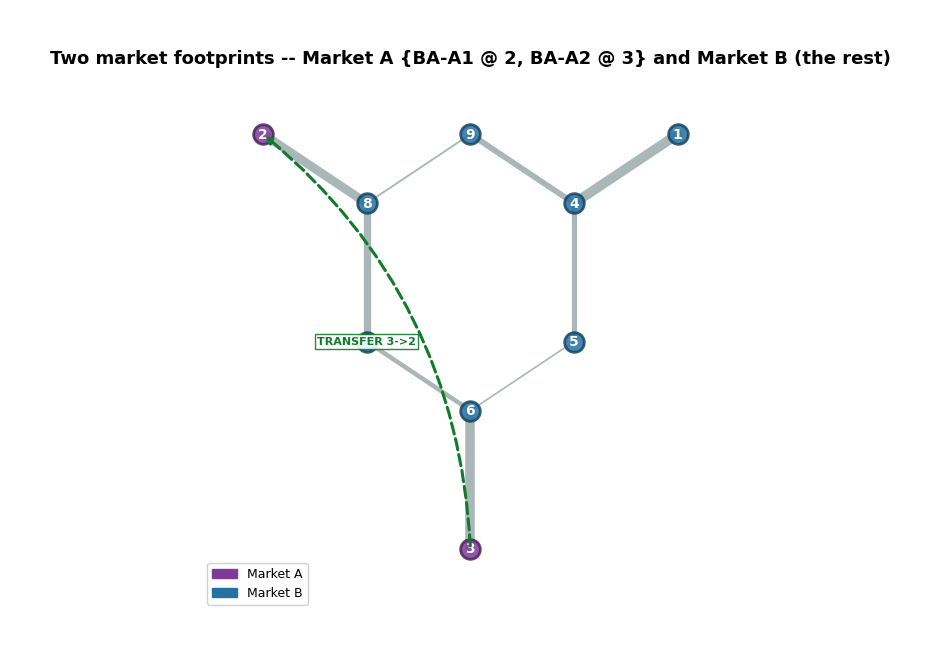

In [4]:
# Configuration map: the two market footprints on the shared network. Market A's two
# balancing authorities (nodes 2 and 3) are NOT electrically connected -- they coordinate
# only through the transfer (dashed, source -> sink), which Market B physically wheels.
# Buses are colored by market; lines by the market whose footprint they sit in (the seam
# between the markets is gray). Edit MKT_DEFS / SOURCE / SINK above and re-run to reshape.
import matplotlib.patches as mpatches
_fpm = fpmod.make(pt9, MKT_DEFS, MKT_COLORS, tie_label='seam')
_bcol = {b: MKT_COLORS[_fpm.fp_of(b)] for b in pt9.buses}
fig, ax = plot_network_topology(
    build_network(MKT_B_RATING), supply_by_bus={}, demand_by_bus={},
    bus_colors=_bcol, bus_coords=COORDS,
    line_flows={l: 0.0 for l in pt9.lines}, line_widths=susceptance_widths(pt9),
    line_colors=_fpm.line_colors(pt9),
    title='Two market footprints -- Market A {BA-A1 @ 2, BA-A2 @ 3} and Market B (the rest)')
ax.annotate('', xy=COORDS[SINK], xytext=COORDS[SOURCE],
            arrowprops=dict(arrowstyle='-|>', color='#117A2B', lw=2.2, ls='--',
                            connectionstyle='arc3,rad=0.22'), zorder=8)
_mx, _my = (COORDS[SOURCE][0] + COORDS[SINK][0]) / 2, (COORDS[SOURCE][1] + COORDS[SINK][1]) / 2
ax.text(_mx, _my, f'TRANSFER {SOURCE}->{SINK}', fontsize=8, fontweight='bold', color='#117A2B',
        ha='center', va='center', bbox=dict(fc='white', ec='#117A2B', alpha=0.9, pad=1.5), zorder=9)
ax.legend(handles=[mpatches.Patch(color=MKT_COLORS[m], label=m) for m in MKT_DEFS],
          loc='lower left', fontsize=9, framealpha=0.9)
plt.show()

## 2. The transfer, market by market

The arrangement follows 205's sandbox. The
positions ledger comes first, then a network + nodal-dispatch composite for each view:
**Market A** (the transport), **Market B** (the wheeling), **Combined** (the one line
under both dispatches), and **Unified** (one engine for reference). Every composite
carries a **Transfers** inset: the two Market A BAs as bubbles and the transfer
between them. This is the day-ahead, matched base case, where the self-schedule equals
the cleared transfer, $E_B = E_A = E$.

In [5]:
# Market A -- an EDAM-literal clear over {2,3}, monitoring no lines: one power balance
# per BA and a scheduled transfer on their declared interface, so the only constraint
# is the released capacity and node 3 / node 2 separate by mu_T.
engA = wm.make_engine('Market A', MKT_DEFS['Market A'], gen_fleet=GEN_FLEET, loads=LOADS, activated=[])
A_AREAS = {'BA-A2': [SOURCE], 'BA-A1': [SINK]}       # each Market A BA its own balance
A_IFC   = tuple(sorted(A_AREAS))                     # the one declared interface
rA   = solve_engine_transfers(pt9, engA, A_AREAS, {A_IFC: EBAR})   # capped -> mu_T > 0
E    = abs(rA.transfers[A_IFC]); muT = abs(rA.transfer_duals[A_IFC])
# Market B -- wheels the transfer as a self-schedule (inject +E at source, withdraw -E at sink).
engB = wm.make_engine('Market B', MKT_DEFS['Market B'], gen_fleet=GEN_FLEET, loads=LOADS)
rB   = solve_engine_dispatch(pt9, engB, exo={SOURCE: +E, SINK: -E}, shed_price=150.0)
wheel = (rB.lmp[SINK] - rB.lmp[SOURCE]) * E
# Unified (reference) + autarky (each BA alone).
unified = wm.make_engine('UNIFIED', buses=pt9.buses, gen_fleet=GEN_FLEET, loads=LOADS)
resU = solve_engine_dispatch(pt9, unified, shed_price=150.0)
_, indep = ra.independent_clear(fp_ba, MKT_B_RATING, gen_fleet=GEN_FLEET, loads=LOADS, shed_price=150.0)
print(f'Market A: lambda_{SOURCE}=${rA.lmp[SOURCE]:.0f}  lambda_{SINK}=${rA.lmp[SINK]:.0f}  '
      f'E={E:.0f} MW  mu_T=${muT:.0f}  transfer rent=${muT*E:,.0f}/h')
print(f'Market B: lambda_{SOURCE}=${rB.lmp[SOURCE]:.0f}  lambda_{SINK}=${rB.lmp[SINK]:.0f}  '
      f'Market B settlement cost the transaction covers = ${wheel:,.0f}/h')

# Transport-bubbles inset values (same on every composite): the two Market A BAs.
import numpy as np
def _tam(bus): return sum(g.get('p_nom', 0.0) for g in _sup.get(bus, [])) + LOADS.get(bus, 0.0)
INS_LABELS  = ('BA-A2', 'BA-A1')
INS_TAM     = {'BA-A2': _tam(SOURCE), 'BA-A1': _tam(SINK)}
INS_SURPLUS = {'BA-A2': +E, 'BA-A1': -E}
INS_COLORS  = {'BA-A2': BA_COLORS['BA-A2'], 'BA-A1': BA_COLORS['BA-A1']}
INS_TIECAP  = max(_sup[SOURCE][0]['p_nom'] - LOADS[SOURCE], EBAR)   # node-3 surplus capacity
def add_inset(fig):
    figs.transfer_inset(fig.add_axes(figs.INSET_RECT), INS_LABELS, INS_TAM,
                        INS_SURPLUS, E, EBAR, muT, INS_COLORS, INS_TIECAP)

# Reusable Combined view: the ACTUAL total flows of Market A's transport + a given
# Market B dispatch on the one line, each bus at its home-market LMP, with the
# transport inset. Returns (fig, flows). Overloaded lines draw red.
def combined_view(rB_, suptitle, eng_b=engB):
    p_ = np.zeros(pt9.n_bus)
    for r_ in (rA, rB_):
        for b, mw in r_.gen_by_bus.items():  p_[pt9.bus_idx[b]] += mw
        for b, mw in r_.load_by_bus.items(): p_[pt9.bus_idx[b]] -= mw
    f_ = pt9.ptdf @ p_
    host_ = {b: (rA.lmp[b] if b in MKT_DEFS['Market A'] else rB_.lmp[b]) for b in pt9.buses}
    sup_, dem_ = {}, {}
    for e_, r_ in ((engA, rA), (eng_b, rB_)):
        s_, d_ = to_supply_demand(e_, r_); sup_.update(s_); dem_.update(d_)
    fig_, _ = plot_combined_letter(
        net9, sup_, dem_, bus_colors=BUS_COLORS_3BA, bus_lmps=host_,
        line_flows={l: float(x) for l, x in zip(pt9.lines, f_)},
        line_widths=susceptance_widths(pt9), line_colors=fp_mkt.line_colors(pt9),
        constrained_lines={l for l, x in zip(pt9.lines, f_) if abs(x) > pt9.s_nom[pt9.line_idx[l]] + 1e-6},
        flows=nodal_plot.compute_ptdf_flows(net9, sup_, dem_),
        lmp_line=True, bus_groups=fp_mkt.groups(pt9), group_colors=dict(MKT_COLORS), show_group_labels=False,
        all_buses=pt9.buses, sector_order=RING_ORDER, bus_coords=COORDS, center_bus=CENTER_BUS,
        annotate_roles=True, axis_key=True,
        title_left='Network -- ACTUAL total flows (gens & loads counted once)', suptitle=suptitle)
    add_inset(fig_)
    return fig_, f_

INFO:ieee9_network:Imported IEEE 9-bus: 9 buses, 3 gens, 3 loads, 9 lines


Market A: lambda_3=$25  lambda_2=$48  E=30 MW  mu_T=$23  transfer rent=$690/h

Market B: lambda_3=$20  lambda_2=$35  Market B settlement cost the transaction covers = $450/h

### The transaction, from a BA-B transmission customer's view

The party that moves the power is a transmission customer of BA-B. It holds the
3$\to$2 transfer right in Market A and self-schedules the physical delivery in
Market B. The formulation of its day-ahead P&L follows, then the same expression
evaluated at this example's volumes and prices.

**Variables.** $E$ = scheduled transfer (MW), node 3 $\to$ node 2 (day-ahead,
matched: $E_B = E_A = E$); $\mu_T = \lambda^A_2 - \lambda^A_3$ = the Market A
transfer-constraint price from (1); $\lambda^B_n$ = the Market B LMP at bus $n$.

**Transfer right (Market A).** Holding the right across the binding constraint pays

$$R_A \;=\; \mu_T\,E. \qquad\qquad (3)$$

*In words.* The customer's Market A transfer-right revenue $R_A$ is the transfer price $\mu_T$ times the scheduled volume $E$.

**Physical settlement (Market B), day-ahead.** As a self-schedule the customer is
*paid* to inject $E$ at the source and *pays* to withdraw $E$ at the sink,

$$S_B \;=\; \lambda^B_{\text{src}}\,E \;-\; \lambda^B_{\text{snk}}\,E
       \;=\; -\,\big(\lambda^B_{\text{snk}} - \lambda^B_{\text{src}}\big)\,E. \qquad (4)$$

*In words.* The customer's Market B physical settlement $S_B$ is the source price $\lambda^B_{\text{src}}$ times the injected volume $E$, less the sink price $\lambda^B_{\text{snk}}$ times the withdrawn volume $E$. That equals minus the sink-to-source basis $(\lambda^B_{\text{snk}}-\lambda^B_{\text{src}})$ times the volume $E$.

Under the extended day-ahead market's base-case rules the day-ahead congestion revenue
is **allocated back to the self-scheduler**:

$$A_B \;=\; +\,\big(\lambda^B_{\text{snk}} - \lambda^B_{\text{src}}\big)\,E,
  \qquad S_B + A_B \;=\; 0. \qquad (5)$$

*In words.* The day-ahead congestion allocation $A_B$ returned to the self-scheduler is the sink-to-source basis $(\lambda^B_{\text{snk}}-\lambda^B_{\text{src}})$ times the volume $E$. Note that $A_B$ is the exact mirror of the physical settlement $S_B$, so the two sum to zero.

**Net to the transaction (day-ahead).** The wheel is congestion-neutral, so the
transaction keeps the whole transfer rent:

$$\Pi \;=\; R_A + S_B + A_B \;=\; \mu_T\,E. \qquad\qquad (6)$$

*In words.* The transaction's day-ahead payoff $\Pi$ is the transfer-right revenue $R_A$ plus the physical settlement $S_B$ plus the congestion allocation $A_B$. The payoff collapses to the transfer price $\mu_T$ times the volume $E$, because $S_B$ and $A_B$ cancel and the transaction keeps only the transfer rent.

The scope of this section is the day-ahead, matched case. The real-time exposure is
taken up in Sections 4 and 5, where the self-schedule $E_B$ and the cleared transfer
$E_A$ differ and the congestion no longer returns to the customer.

In [6]:
laB_s, laB_k = rB.lmp[SOURCE], rB.lmp[SINK]
cong = (laB_k - laB_s) * E                          # day-ahead congestion the self-schedule crosses
pnl = pd.DataFrame(
    [('Transfer right (Market A)               R_A = mu_T x E',
      round(E, 0), round(muT, 1), round(muT * E, 1)),
     (f'Self-schedule  inject @ src (DA)        +lambdaB_{SOURCE} x E',
      round(E, 0), round(laB_s, 1), round(laB_s * E, 1)),
     (f'Self-schedule  withdraw @ snk (DA)      -lambdaB_{SINK} x E',
      round(E, 0), round(laB_k, 1), round(-laB_k * E, 1)),
     ('DA congestion allocated to self-sched   +(lambdaB_snk - lambdaB_src) x E',
      round(E, 0), round(laB_k - laB_s, 1), round(cong, 1))],
    columns=['term', 'quantity E (MW)', 'price ($/MWh)', '$/h']).set_index('term')
net_txn = muT * E + laB_s * E - laB_k * E + cong     # = mu_T x E (the wheel nets to zero)
pnl.loc['  Net to the transaction (day-ahead)    Pi = mu_T x E'] = ['', '', round(net_txn, 1)]
display(pnl)
print(f'Day-ahead wheel is congestion-neutral: the self-schedule pays ${cong:,.0f}/h of '
      f'congestion, and the base-case rule returns ${cong:,.0f}/h to the self-scheduler -> net $0.')
print(f'Pi = mu_T x E = ${muT:.0f} x {E:.0f} = ${net_txn:,.0f}/h -- the full transfer rent. '
      f'The real cost appears only in real time, on any E_A - E_B mismatch (Sections 4-5).')

,quantity E (MW),price ($/MWh),$/h
term,,,
Transfer right (Market A) R_A = mu_T x E,30.0,23.0,690.0
Self-schedule inject @ src (DA) +lambdaB_3 x E,30.0,20.0,600.0
Self-schedule withdraw @ snk (DA) -lambdaB_2 x E,30.0,35.0,-1050.0
DA congestion allocated to self-sched +(lambdaB_snk - lambdaB_src) x E,30.0,15.0,450.0
Net to the transaction (day-ahead) Pi = mu_T x E,,,690.0


Day-ahead wheel is congestion-neutral: the self-schedule pays $450/h of congestion, and the base-case rule returns $450/h to the self-scheduler -> net $0.

Pi = mu_T x E = $23 x 30 = $690/h -- the full transfer rent. The real cost appears only in real time, on any E_A - E_B mismatch (Sections 4-5).

### Positions, balancing authority by balancing authority

The table reports how the three BAs settle under three cases: 1) autarky, each BA
alone, 2) the two-market transfer, and 3) a unified clearing. Consumer payments are
negative. Each BA's **net settlement position** $N_a=L_a-G_a$ is its residual. Under
autarky each BA is balanced, so its net settlement position equals its own internal
congestion rent. Once power moves between BAs the net settlement position is dominated
by the energy of the interchange, and only the system total $\sum_a N_a$ is congestion
revenue. The day-ahead congestion the self-schedule creates on BA-B's path is allocated
to the transaction, the self-scheduler, so the **Transaction** row keeps Market A's
transfer rent $\mu_T E$ in full and BA-B keeps only its own internal line rent.
Positions sum to $-$(production cost).

In [7]:
def _ba_block(ba, buses, r_):
    cons = sum(r_.lmp[b] * LOADS.get(b, 0.0) for b in buses)
    grev = sum(r_.lmp[b] * r_.gen_by_bus.get(b, 0.0) for b in buses)
    gcst = sum(COST.get(b, 0.0) * r_.gen_by_bus.get(b, 0.0) for b in buses)
    return cons, grev, gcst

def _positions(case):
    out = {}
    if case == 'autarky':
        for ba in BA_DEFS:
            r_ = indep[ba]
            cons, grev, gcst = _ba_block(ba, BA_DEFS[ba], r_)
            out[(ba, 'consumers')] = -cons; out[(ba, 'gen revenue')] = grev
            out[(ba, 'gen profit')] = grev - gcst
            out[(ba, 'net settlement position')] = cons - grev   # own internal rent
        out[('Transaction', 'net')] = 0.0
        out[('Total', 'production cost')] = -sum(indep[ba].total_cost for ba in BA_DEFS)
    elif case == 'unified':
        for ba in BA_DEFS:
            cons, grev, gcst = _ba_block(ba, BA_DEFS[ba], resU)
            out[(ba, 'consumers')] = -cons; out[(ba, 'gen revenue')] = grev
            out[(ba, 'gen profit')] = grev - gcst
            out[(ba, 'net settlement position')] = cons - grev
        out[('Transaction', 'net')] = 0.0
        out[('Total', 'production cost')] = -resU.total_cost
    else:  # transfer
        # Market A single-node BAs (no rent kept; the separation IS the transfer rent)
        for ba, bus in (('BA-A1', SINK), ('BA-A2', SOURCE)):
            lam = rA.lmp[bus]; d = LOADS.get(bus, 0.0); g = rA.gen_by_bus.get(bus, 0.0)
            out[(ba, 'consumers')] = -lam * d; out[(ba, 'gen revenue')] = lam * g
            out[(ba, 'gen profit')] = (lam - COST.get(bus, 0.0)) * g
            out[(ba, 'net settlement position')] = 0.0
        consB, grevB, gcstB = _ba_block('BA-B', BA_DEFS['BA-B'], rB)
        out[('BA-B', 'consumers')] = -consB; out[('BA-B', 'gen revenue')] = grevB
        out[('BA-B', 'gen profit')] = grevB - gcstB
        # Day-ahead base-case rule: the congestion the self-schedule crosses is allocated
        # back to the self-scheduler (the Transaction), so BA-B keeps only its internal
        # line rent and the Transaction keeps the full transfer rent.
        out[('BA-B', 'net settlement position')] = (consB - grevB)       # internal line rent only
        out[('Transaction', 'net')] = muT * E                            # full transfer rent (DA congestion returned)
        out[('Total', 'production cost')] = -(rA.total_cost + rB.total_cost)
    return out

led = pd.DataFrame({'autarky': _positions('autarky'),
                    'two-market transfer': _positions('transfer'),
                    'unified': _positions('unified')}).T
led.columns = pd.MultiIndex.from_tuples(led.columns)
# total position per BA = consumers + gen profit + net settlement position
for ba in BA_DEFS:
    led[(ba, 'total position')] = led[(ba, 'consumers')] + led[(ba, 'gen profit')] + led[(ba, 'net settlement position')]
led = led.sort_index(axis=1)
_net = sum(led[(ba, 'total position')] for ba in BA_DEFS) + led[('Transaction', 'net')]
print('closure check  (sum of total positions  vs  -production cost):')
for case in led.index:
    print(f'  {case:22s} {_net[case]:>12,.1f}  vs  {led[("Total","production cost")][case]:>12,.1f}')
display(led.round(0) + 0.0)

closure check  (sum of total positions  vs  -production cost):

  autarky                   -14,355.0  vs     -14,355.0

  two-market transfer       -13,776.9  vs     -13,776.9

  unified                   -13,349.6  vs     -13,349.6

BA-A1                                                                   BA-A2                                                 \
                    consumers gen profit gen revenue net settlement position total position consumers gen profit gen revenue net settlement position   
autarky               -2880.0        0.0      2880.0                     0.0        -2880.0   -3000.0        0.0      3000.0                     0.0   
two-market transfer   -2880.0        0.0      1440.0                     0.0        -2880.0   -3000.0        0.0      3750.0                     0.0   
unified               -2100.0        0.0         0.0                  2100.0            0.0   -3000.0        0.0      3563.0                  -563.0   

                                        BA-B                                                                         Total Transaction  
                    total position consumers gen profit gen revenue net settlement position total position production cost         net  
autarky                    -3000.0  -11025.0     2550.0     11025.0                     0.0        -8475.0        -14355.0         0.0  
two-market transfer        -3000.0   -9745.0        0.0      8587.0                  1158.0        -8587.0        -13777.0       690.0  
unified                    -3563.0  -10172.0      850.0     10636.0                  -464.0        -9786.0        -13350.0         0.0

### Stepping through the views

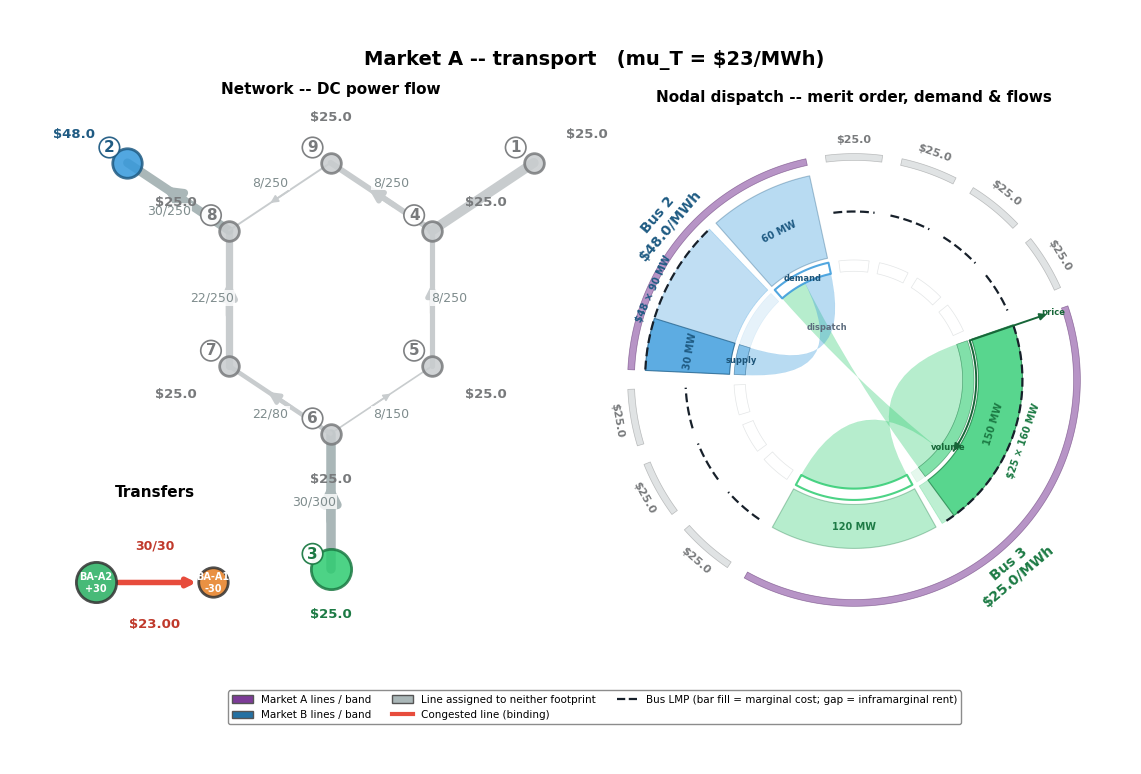

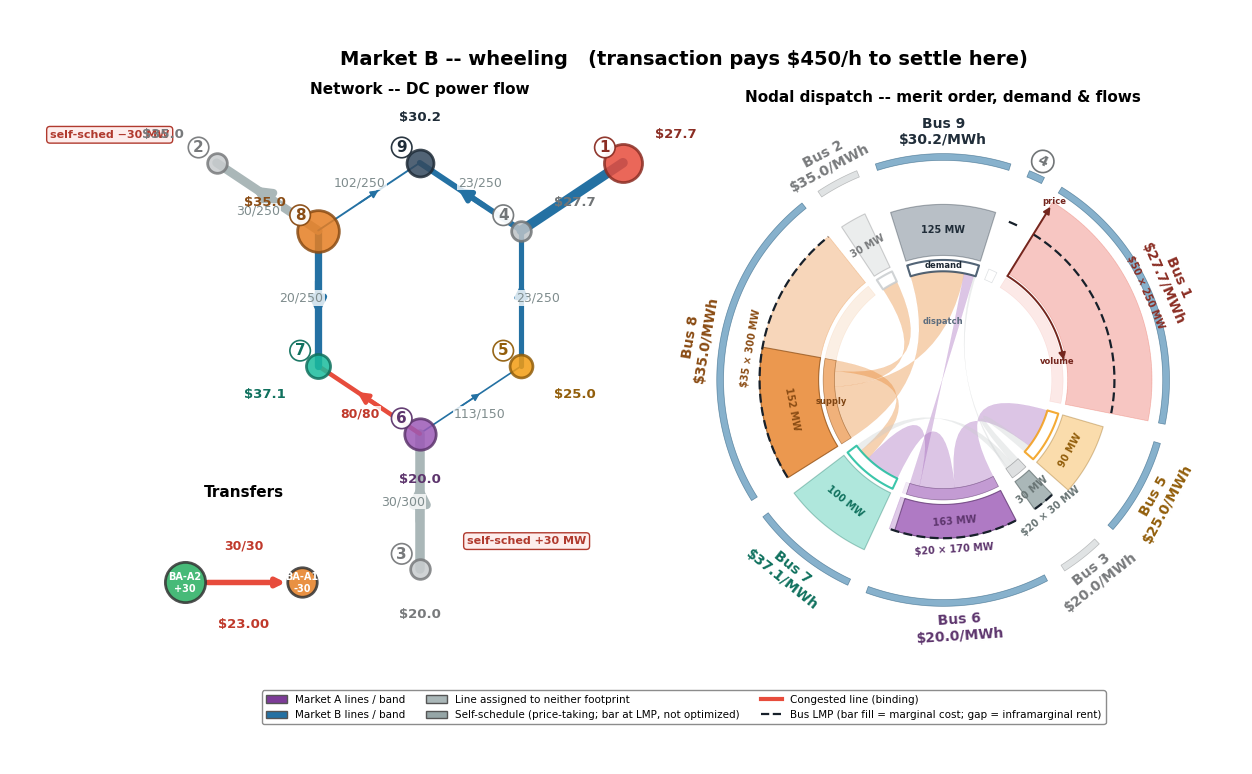

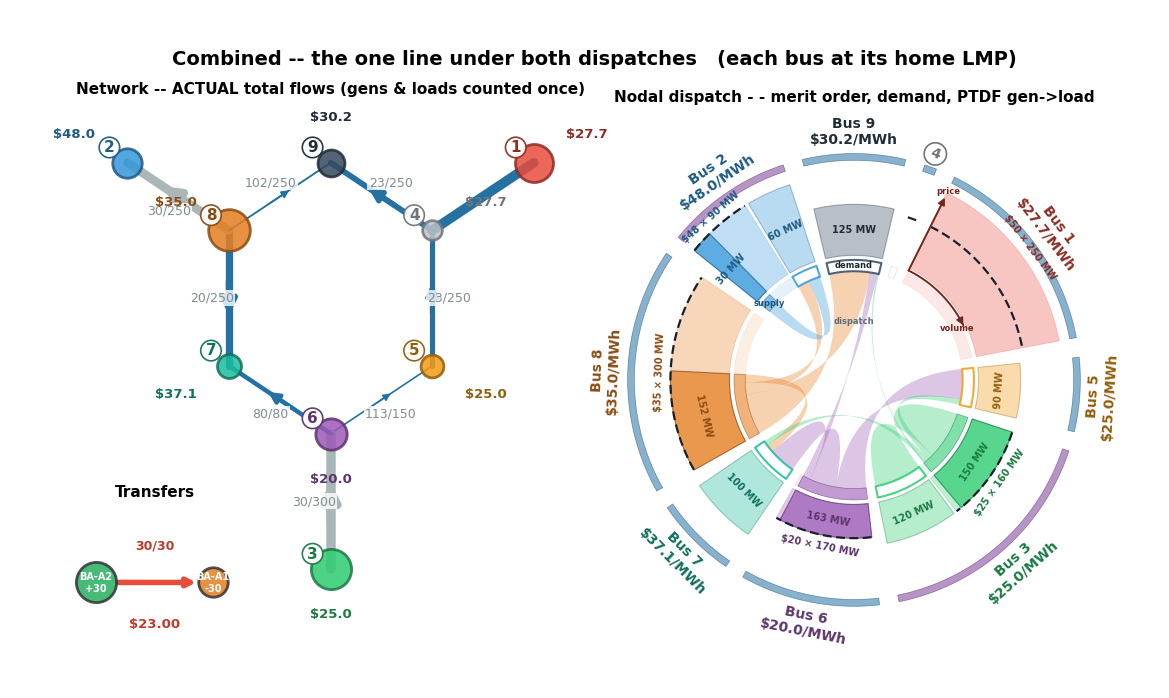

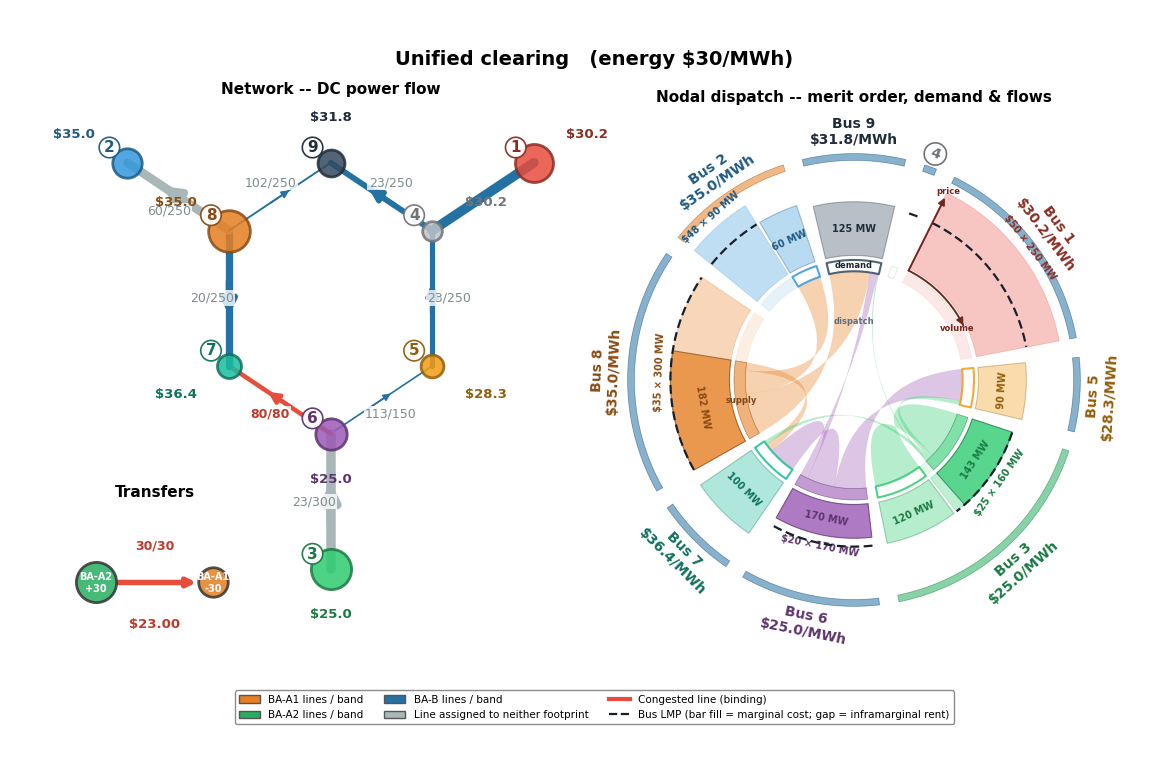

In [8]:
# (1) Market A -- the transport (rest grayed); the transfer separates node 3 / node 2.
figA = figs.footprint_figure(net9, pt9, fp_mkt, engA, rA, highlight='Market A',
                             bus_colors=BUS_COLORS_3BA,
                             suptitle=f'Market A -- transport   (mu_T = ${muT:.0f}/MWh)')
add_inset(figA); plt.show()

# (2) Market B -- wheeling the transfer as a self-schedule (the transaction settles here).
figB = figs.footprint_figure(net9, pt9, fp_mkt, engB, rB, highlight='Market B',
                             bus_colors=BUS_COLORS_3BA, exo_sched={SOURCE: +E, SINK: -E},
                             suptitle=f'Market B -- wheeling   (transaction pays ${wheel:,.0f}/h to settle here)')
add_inset(figB); plt.show()

# (3) Combined -- the one line under both dispatches; each bus at its HOME market LMP.
figC, f_act = combined_view(rB, 'Combined -- the one line under both dispatches   (each bus at its home LMP)')
plt.show()

# (4) Unified -- one engine over every bus and constraint.
figU = figs.footprint_figure(net9, pt9, fp_ba, unified, resU, bus_colors=BUS_COLORS_3BA,
                             suptitle=f'Unified clearing   (energy ${resU.energy_price:.0f}/MWh)')
add_inset(figU); plt.show()

## 3. Dispatch interference and inefficient accommodation

### Superposition -- Market A's dispatch on Market B's transmission elements

In Section 2 Market B co-optimized with the transfer and carried it securely. Market B
does not dispatch the transfer. Market B only wheels it. If Market B instead clears
blind, serving only its own load, Market A's transport dispatch superposes on the
shared line. Each market's own clear is then feasible, and the physical flow on the
path line exceeds its limit. In the four views below, Market A and Market B each clear
within limits, the Combined line overloads, and the Unified clear is secure.

In [9]:
# Market B BLIND: clears its own load on the same network, unaware of the transfer.
rB_blind = solve_engine_dispatch(pt9, engB, shed_price=150.0)
pf = physical_flows(pt9, [rA, rB_blind])     # superpose Market A + Market B-blind flows
over = pf[pf.overload]
print('superposition overloads (Market A transport + Market B blind):',
      list(over.index) if len(over) else 'none')
disp = pf[['from', 'to', 'F[Market A]', 'F[Market B]', 'F_phys', 'rating', 'loading_%', 'overload']]
display(disp[(disp['F[Market A]'].abs() > 0.5) | disp['overload']])
print(f'line_4: F[Market A] {pf.loc["line_4","F[Market A]"]:.1f} + '
      f'F[Market B] {pf.loc["line_4","F[Market B]"]:.1f} = {pf.loc["line_4","F_phys"]:.1f} MW '
      f'vs {pf.loc["line_4","rating"]:.0f} MW rating; both markets cleared feasibly.')

superposition overloads (Market A transport + Market B blind):

['line_4']

,from,to,F[Market A],F[Market B],F_phys,rating,loading_%,overload
line,,,,,,,,
line_1,4,5,-7.6,-16.8,-24.4,250.0,10.0,False
line_2,5,6,-7.6,-106.8,-114.4,150.0,76.0,False
line_3,3,6,30.0,0.0,30.0,300.0,10.0,False
line_4,6,7,22.4,63.2,85.6,80.0,107.0,True
line_5,7,8,22.4,-36.8,-14.4,250.0,6.0,False
line_6,8,2,30.0,0.0,30.0,250.0,12.0,False
line_7,8,9,-7.6,108.2,100.6,250.0,40.0,False
line_8,9,4,-7.6,-16.8,-24.4,250.0,10.0,False


line_4: F[Market A] 22.4 + F[Market B] 63.2 = 85.6 MW vs 80 MW rating; both markets cleared feasibly.

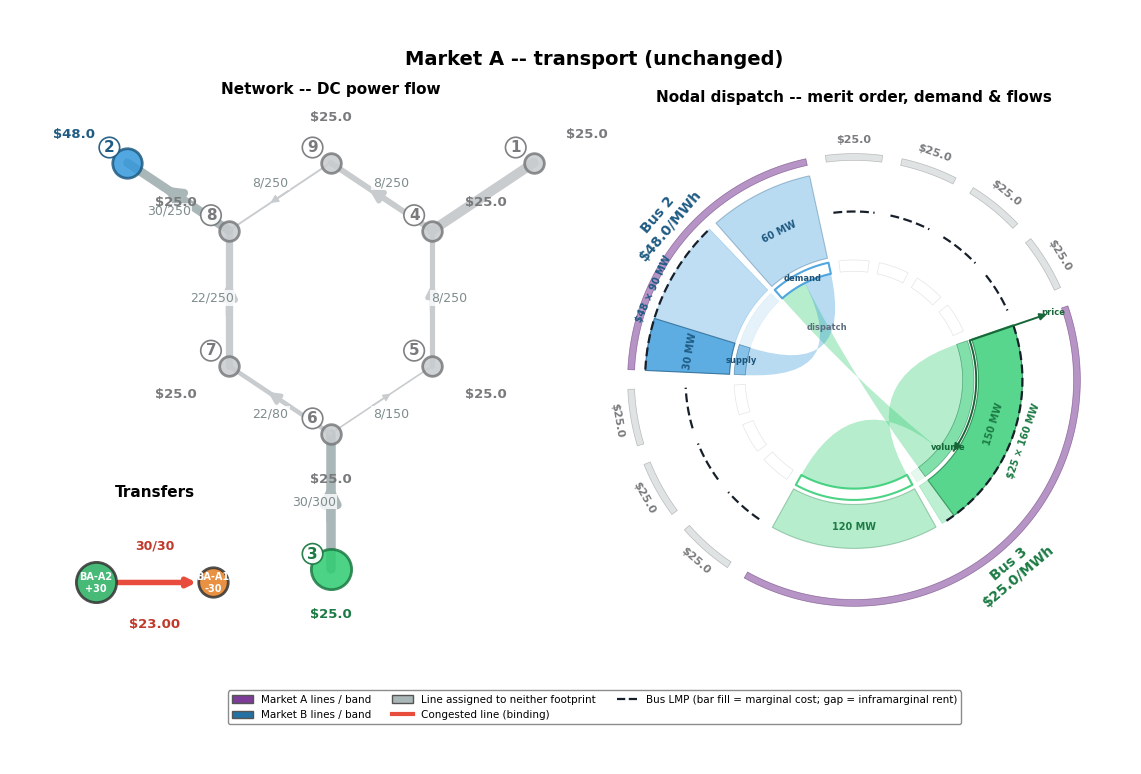

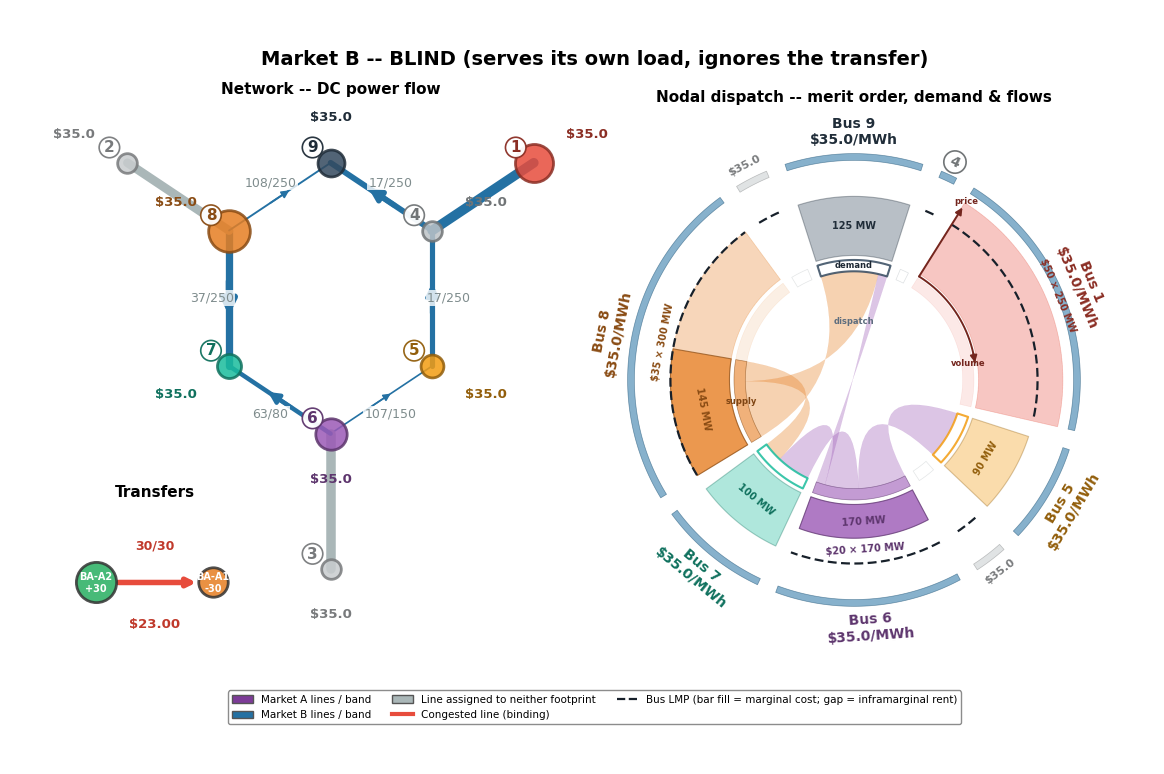

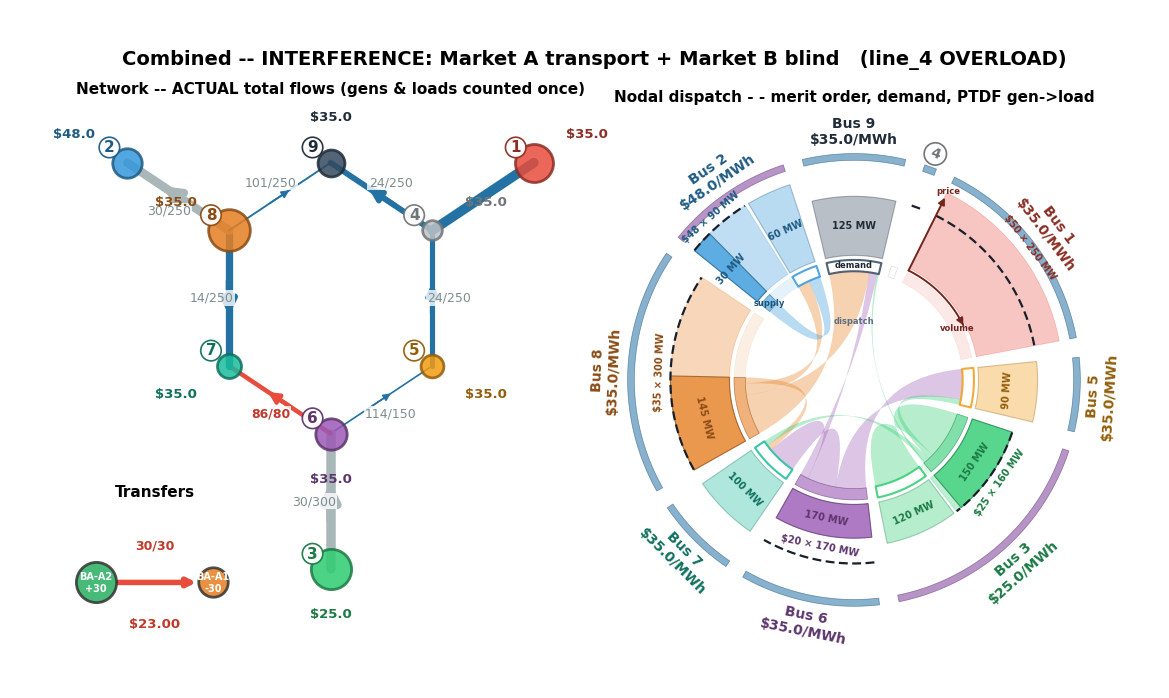

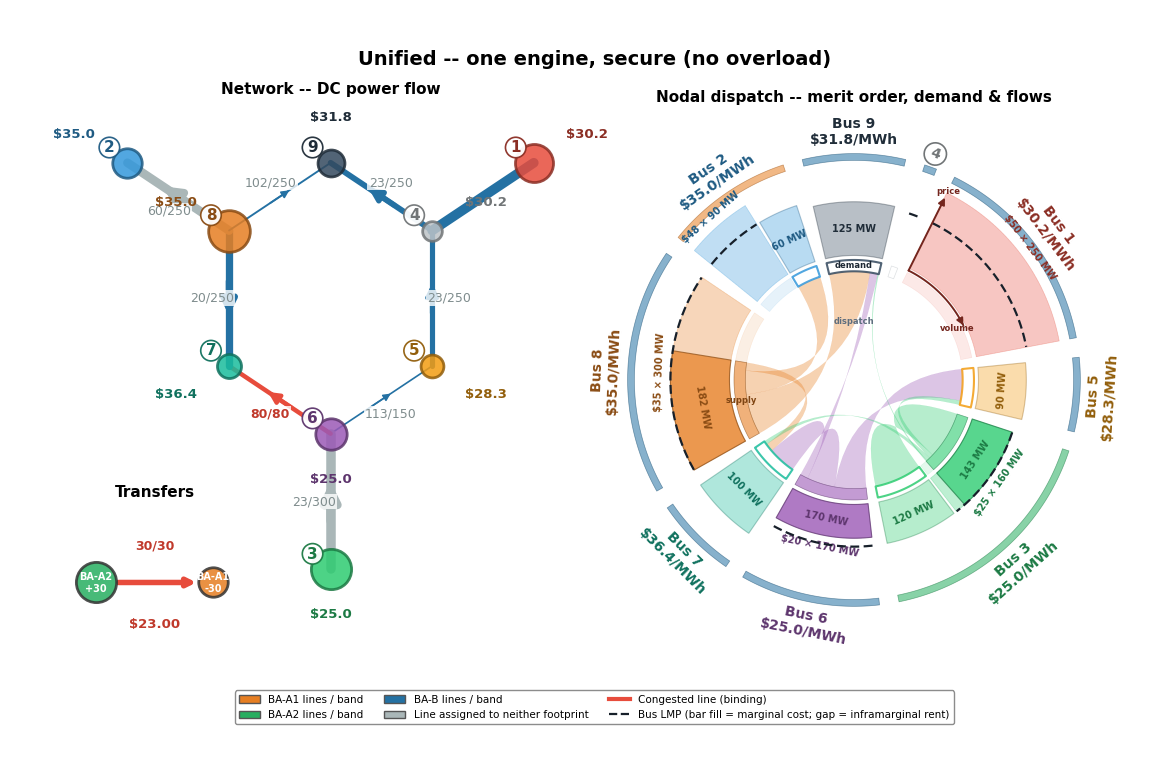

In [10]:
# The interference in the four views: each market is feasible alone, the Combined
# line overloads (line_4 red), the Unified clear is secure.
fA = figs.footprint_figure(net9, pt9, fp_mkt, engA, rA, highlight='Market A',
                           bus_colors=BUS_COLORS_3BA, suptitle='Market A -- transport (unchanged)')
add_inset(fA); plt.show()
fBb = figs.footprint_figure(net9, pt9, fp_mkt, engB, rB_blind, highlight='Market B',
                            bus_colors=BUS_COLORS_3BA,
                            suptitle='Market B -- BLIND (serves its own load, ignores the transfer)')
add_inset(fBb); plt.show()
combined_view(rB_blind, 'Combined -- INTERFERENCE: Market A transport + Market B blind   (line_4 OVERLOAD)')
plt.show()
fUi = figs.footprint_figure(net9, pt9, fp_ba, unified, resU, bus_colors=BUS_COLORS_3BA,
                            suptitle='Unified -- one engine, secure (no overload)')
add_inset(fUi); plt.show()

### Inefficient accommodation -- reserving for the transfer

One response available to Market B is to reserve headroom on the path lines so the
transfer fits, by de-rating those lines before clearing its own dispatch. With $f^T_m$
the megawatts the transfer puts on line $m$, the effective limit becomes

$$\bar F^{\,\text{eff}}_m \;=\; \bar F_m \;-\; \beta\,\big|f^T_m\big|. \qquad\qquad (7)$$

*In words.* Line $m$'s effective rating $\bar F^{\text{eff}}_m$, once Market B reserves headroom for the transfer, is line $m$'s physical rating $\bar F_m$ minus the reservation margin $\beta$ times the absolute forecast transfer flow $\lvert f^T_m\rvert$.

$\beta = 1$ reserves exactly the forecast flow. $\beta > 1$ vacates capacity the
transfer never uses, which forces a more expensive redispatch.

In [11]:
# Coordinated benchmark: Market B co-optimizes WITH the transfer (this is rB from Section 2).
rB_coord = rB
exo_vec = np.zeros(pt9.n_bus)
exo_vec[pt9.bus_idx[SOURCE]] += E; exo_vec[pt9.bus_idx[SINK]] -= E
fT = pt9.ptdf @ exo_vec
PATH = [l for l in pt9.lines
        if abs(fT[pt9.line_idx[l]]) > 1.0 and fp_ba.line_assign.get(l) == 'BA-B']
print('Market B path lines the transfer loads (MW):',
      {l: round(float(fT[pt9.line_idx[l]]), 1) for l in PATH})

def accommodate(beta):
    # De-rate each path line by beta x its forecast transfer flow (reserve headroom),
    # then clear Market B's OWN load on the de-rated network. Returns (net, pt, result).
    rat = dict(MKT_B_RATING)
    for l in PATH:
        rat[l] = max(1.0, pt9.s_nom[pt9.line_idx[l]] - beta * abs(fT[pt9.line_idx[l]]))
    n = wm.build_network(rat); p = compute_ptdf(n, slack_bus='1')
    e = wm.make_engine('Market B', MKT_DEFS['Market B'], gen_fleet=GEN_FLEET, loads=LOADS)
    return n, p, solve_engine_dispatch(p, e, shed_price=150.0)

cost_coord = rB_coord.total_cost
print(f'Market B production cost:  ignore the transfer (beta=0) ${accommodate(0.0)[2].total_cost:,.0f}  ->  '
      f'co-optimized (coordinated) ${cost_coord:,.0f}')

Market B path lines the transfer loads (MW):

{'line_1': -7.6, 'line_2': -7.6, 'line_4': 22.4, 'line_5': 22.4, 'line_7': -7.6, 'line_8': -7.6}

INFO:ieee9_network:Imported IEEE 9-bus: 9 buses, 3 gens, 3 loads, 9 lines


Market B production cost:  ignore the transfer (beta=0) $8,475  ->  co-optimized (coordinated) $8,587

In [12]:
# The price of conservatism: sweep the reservation margin beta.
ladder = []
for beta in [0.0, 0.5, 1.0, 1.5, 2.0]:
    r = accommodate(beta)[2]
    ladder.append({'beta': beta, 'Market B cost ($/h)': round(r.total_cost, 0),
                   'vs coordinated ($/h)': round(r.total_cost - cost_coord, 0),
                   'shed (MW)': round(sum(r.shed_by_bus.values()), 0)})
display(pd.DataFrame(ladder).set_index('beta'))

INFO:ieee9_network:Imported IEEE 9-bus: 9 buses, 3 gens, 3 loads, 9 lines


INFO:ieee9_network:Imported IEEE 9-bus: 9 buses, 3 gens, 3 loads, 9 lines


INFO:ieee9_network:Imported IEEE 9-bus: 9 buses, 3 gens, 3 loads, 9 lines


INFO:ieee9_network:Imported IEEE 9-bus: 9 buses, 3 gens, 3 loads, 9 lines


INFO:ieee9_network:Imported IEEE 9-bus: 9 buses, 3 gens, 3 loads, 9 lines


,Market B cost ($/h),vs coordinated ($/h),shed (MW)
beta,,,
0.0,8475.0,-112.0,0
0.5,8475.0,-112.0,0
1.0,8587.0,0.0,0
1.5,8812.0,225.0,0
2.0,9037.0,450.0,0


INFO:ieee9_network:Imported IEEE 9-bus: 9 buses, 3 gens, 3 loads, 9 lines


Market B de-rates the path lines (reservation, beta=1.0):

{'line_1': '250 -> 242 MW', 'line_2': '150 -> 142 MW', 'line_4': '80 -> 58 MW', 'line_5': '250 -> 228 MW', 'line_7': '250 -> 242 MW', 'line_8': '250 -> 242 MW'}

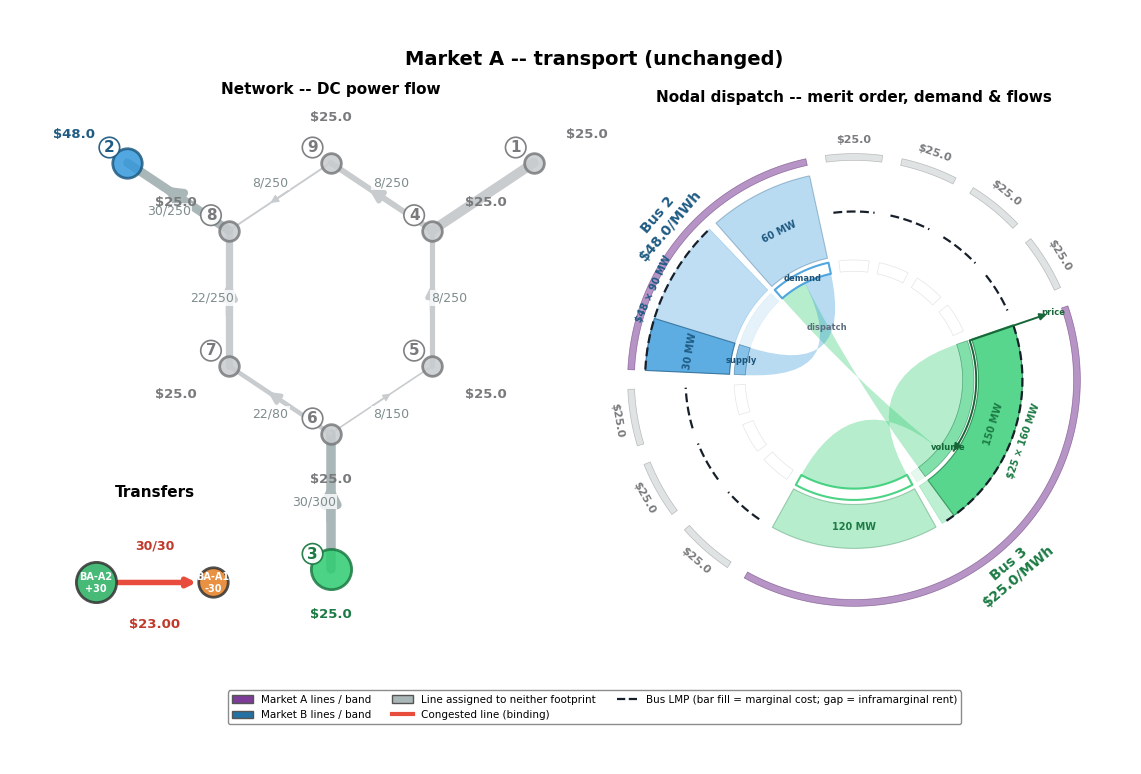

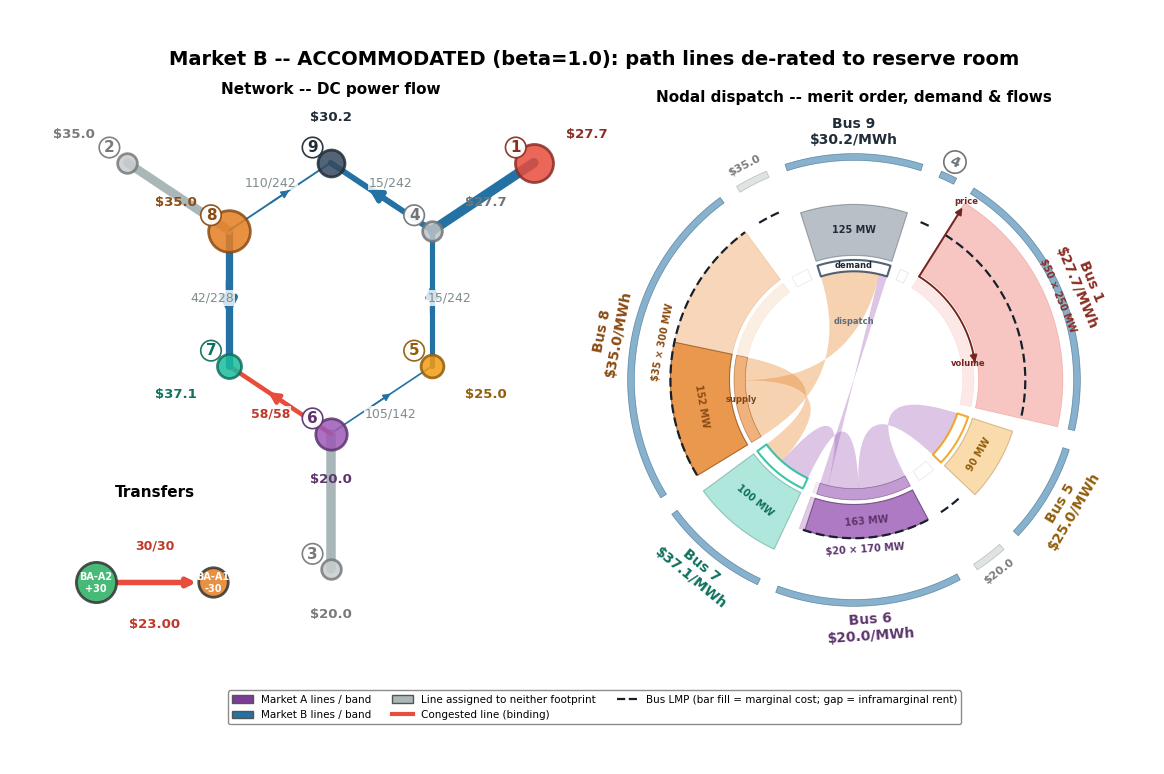

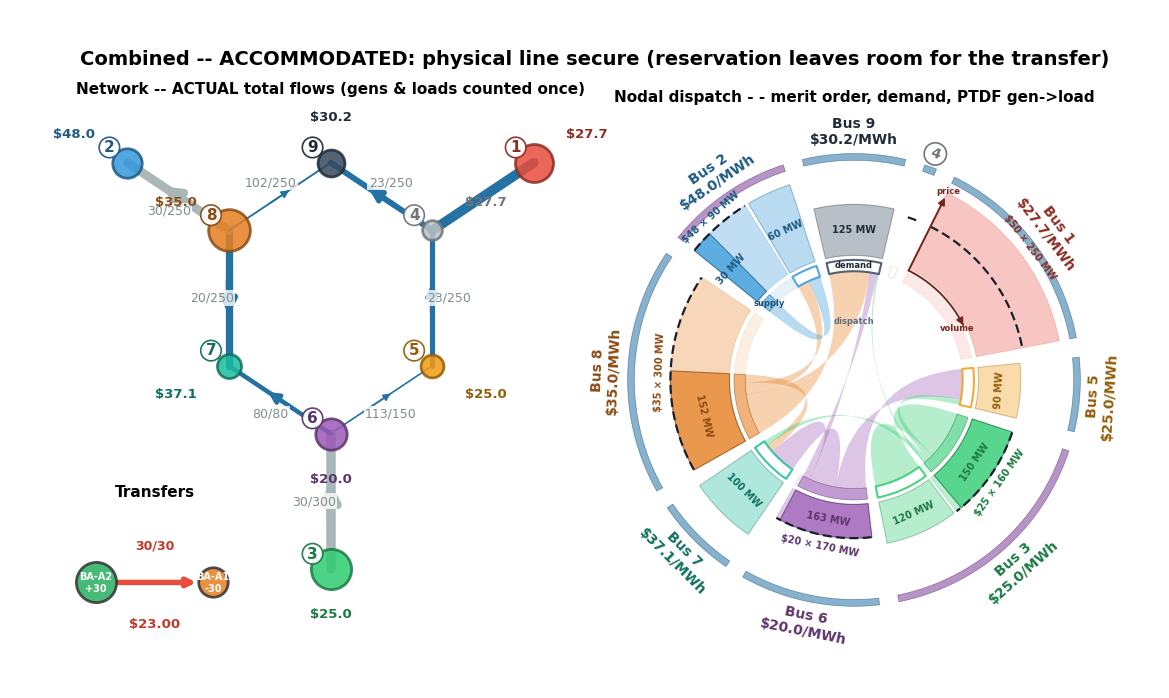

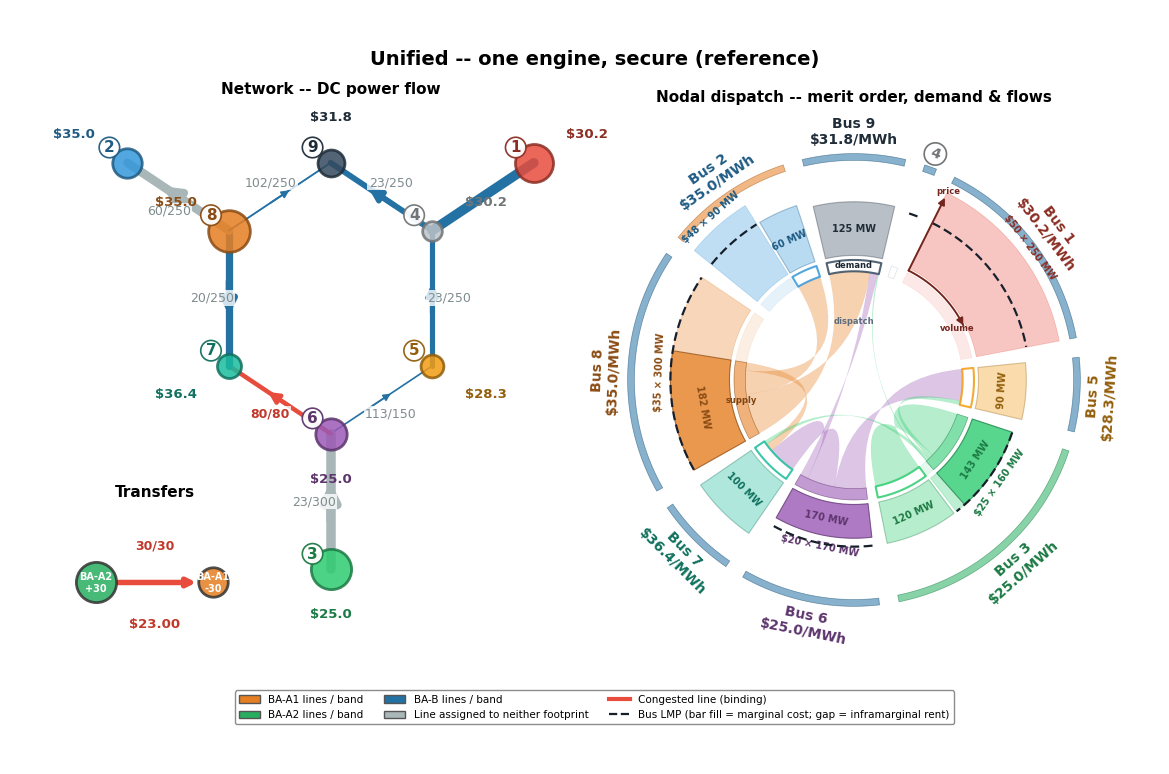

In [13]:
# The accommodation in the four views. Market B DE-RATES the path lines (reduces
# their ratings) to reserve room for the transfer, so its OWN dispatch view shows the
# REDUCED ratings; the physical Combined line then stays secure because the reservation
# left exactly the transfer's room.
ACC_BETA = 1.0
net_acc, pt_acc, rB_acc = accommodate(ACC_BETA)
print(f'Market B de-rates the path lines (reservation, beta={ACC_BETA}):',
      {l: f'{pt9.s_nom[pt9.line_idx[l]]:.0f} -> {pt_acc.s_nom[pt_acc.line_idx[l]]:.0f} MW' for l in PATH})

# (1) Market A -- transport (unchanged).
fA = figs.footprint_figure(net9, pt9, fp_mkt, engA, rA, highlight='Market A',
                           bus_colors=BUS_COLORS_3BA, suptitle='Market A -- transport (unchanged)')
add_inset(fA); plt.show()

# (2) Market B -- on the DE-RATED network: its line ratings are reduced (the reservation),
# and its own dispatch is squeezed into the remaining capacity.
fBa = figs.footprint_figure(net_acc, pt_acc, fp_mkt, engB, rB_acc, highlight='Market B',
                            bus_colors=BUS_COLORS_3BA,
                            suptitle=f'Market B -- ACCOMMODATED (beta={ACC_BETA}): path lines de-rated to reserve room')
add_inset(fBa); plt.show()

# (3) Combined -- the PHYSICAL line: reservation + transfer <= the real rating -> secure.
combined_view(rB_acc, 'Combined -- ACCOMMODATED: physical line secure (reservation leaves room for the transfer)')
plt.show()

# (4) Unified -- one engine, secure (reference).
fUa = figs.footprint_figure(net9, pt9, fp_ba, unified, resU, bus_colors=BUS_COLORS_3BA,
                            suptitle='Unified -- one engine, secure (reference)')
add_inset(fUa); plt.show()

Reserving exactly the forecast flow ($\beta = 1$) carries the transfer at the same cost
as co-optimizing. Reserving more than the forecast flow ($\beta > 1$) vacates capacity
the transfer never uses, and Market B's own dispatch pays for that capacity, so the cost
rises above the coordinated benchmark.

## 4. The risk the transmission customer carries

In the day-ahead a customer whose self-schedule matches the cleared transfer is whole.
It keeps the transfer rent, and the day-ahead congestion is returned to it (Section 2).
The exposure appears when the position is carried into real time, where the congestion
on the price spread no longer returns to the customer and instead accrues to the
balancing authority. The limiting case is a customer that does not lock the volume in a
day-ahead self-schedule, so its whole delivery resettles at the real-time prices. Its
margin per MW is $\mu_T - \text{basis}_B$, the Market A transfer rent it collects minus
the real-time Market B basis it now pays. Both terms are uncertain.
Market A's pricey-BA cost $c_2$ sets $\mu_T = c_2 - 25$. Market B's load drives the
basis $\lambda^B_2 - \lambda^B_3$ the delivery crosses (and the transfer itself loads
those lines, so the basis rises with $E$). The payoff is

$$\Pi(E) = E\,\big(\mu_T - \text{basis}_B(E)\big).$$

Revenue grows with $E$, and so do the real-time basis and the spread of outcomes.
A risk-averse customer trades the mean against that spread.

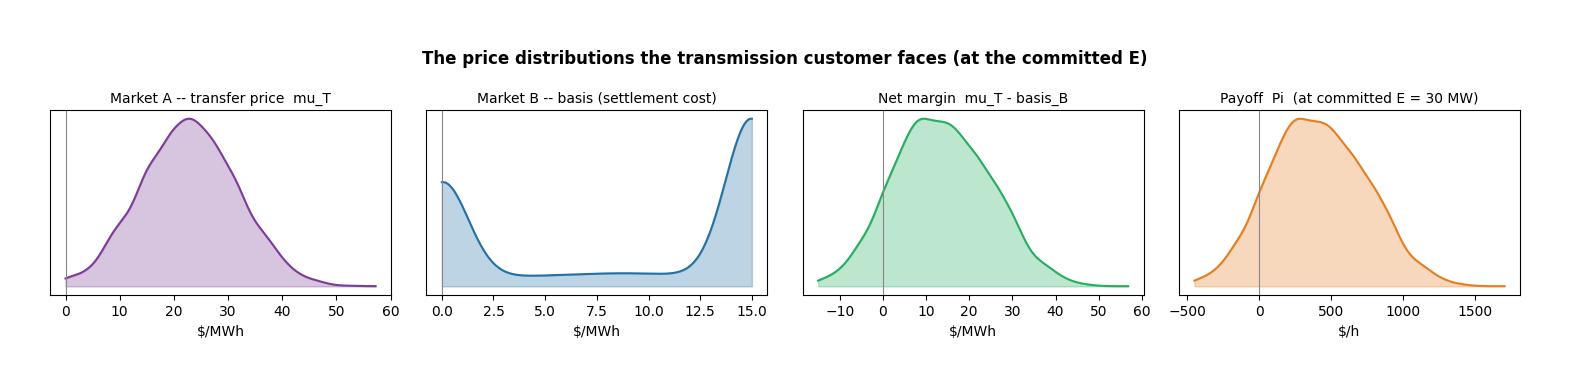

at E=30 MW:  E[mu_T]=$22.9  E[basis_B]=$9.0  E[margin]=$13.8/MWh  E[Pi]=$415/h  P(Pi<0)=10%

In [14]:
from scipy.stats import gaussian_kde
# -- EDIT -- the two uncertainties (realized AFTER E is committed) -----------
C2_MEAN, C2_SD = 48.0, 9.0     # Market A pricey-BA marginal cost  -> mu_T = c2 - 25
SB_MEAN, SB_SD = 1.06, 0.07    # Market B load scale -> the congestion basis it crosses
GAMMAS = [0.0, 0.006, 0.018]   # risk-aversion levels (0 = risk-neutral)
N_MC   = 5000
# ---------------------------------------------------------------------------
E_grid  = np.linspace(0, 40, 21)                                  # committed volume (node-3 surplus = 40)
sB_grid = np.linspace(SB_MEAN - 4 * SB_SD, SB_MEAN + 4 * SB_SD, 19)

def marketB_basis(e, sb):
    loads_s = {b: (LOADS[b] * sb if b in MKT_DEFS['Market B'] else LOADS[b]) for b in LOADS}
    eng = wm.make_engine('Market B', MKT_DEFS['Market B'], gen_fleet=GEN_FLEET, loads=loads_s)
    r = solve_engine_dispatch(pt9, eng, exo=({SOURCE: +e, SINK: -e} if e > 1e-6 else None), shed_price=150.0)
    return r.lmp[SINK] - r.lmp[SOURCE]

basis_grid = np.array([[marketB_basis(e, sb) for sb in sB_grid] for e in E_grid])   # (nE, nS)

np.random.seed(0)
c2 = np.random.normal(C2_MEAN, C2_SD, N_MC)
sb = np.random.normal(SB_MEAN, SB_SD, N_MC)
muT_draw = np.maximum(c2 - 25.0, 0.0)                                    # transfer price
basis_E  = np.vstack([np.interp(sb, sB_grid, basis_grid[i]) for i in range(len(E_grid))])  # (nE, N_MC)
payoff   = E_grid[:, None] * (muT_draw[None, :] - basis_E)               # (nE, N_MC)

# Four induced distributions at the committed Ebar.
iE = int(np.argmin(np.abs(E_grid - EBAR)))
margin = muT_draw - basis_E[iE]
def _dens(a, data, title, color, xlabel):
    if np.std(data) < 1e-6:
        a.axvline(float(np.mean(data)), color=color, lw=2)
    else:
        xs = np.linspace(data.min(), data.max(), 200); ys = gaussian_kde(data)(xs)
        a.fill_between(xs, ys, color=color, alpha=0.3); a.plot(xs, ys, color=color)
    a.axvline(0, color='#888', lw=0.8); a.set_title(title, fontsize=10)
    a.set_xlabel(xlabel); a.set_yticks([])
fig, ax = plt.subplots(1, 4, figsize=(15, 3.1))
_dens(ax[0], muT_draw,    'Market A -- transfer price  mu_T',        '#7D3C98', '$/MWh')
_dens(ax[1], basis_E[iE], 'Market B -- basis (settlement cost)',     '#2471A3', '$/MWh')
_dens(ax[2], margin,      'Net margin  mu_T - basis_B',              '#27AE60', '$/MWh')
_dens(ax[3], payoff[iE],  f'Payoff  Pi  (at committed E = {EBAR:.0f} MW)', '#E67E22', '$/h')
fig.suptitle('The price distributions the transmission customer faces (at the committed E)',
             fontweight='bold')
plt.tight_layout(); plt.show()
print(f'at E={EBAR:.0f} MW:  E[mu_T]=${muT_draw.mean():.1f}  E[basis_B]=${basis_E[iE].mean():.1f}  '
      f'E[margin]=${margin.mean():.1f}/MWh  E[Pi]=${payoff[iE].mean():,.0f}/h  '
      f'P(Pi<0)={100*(payoff[iE] < 0).mean():.0f}%')

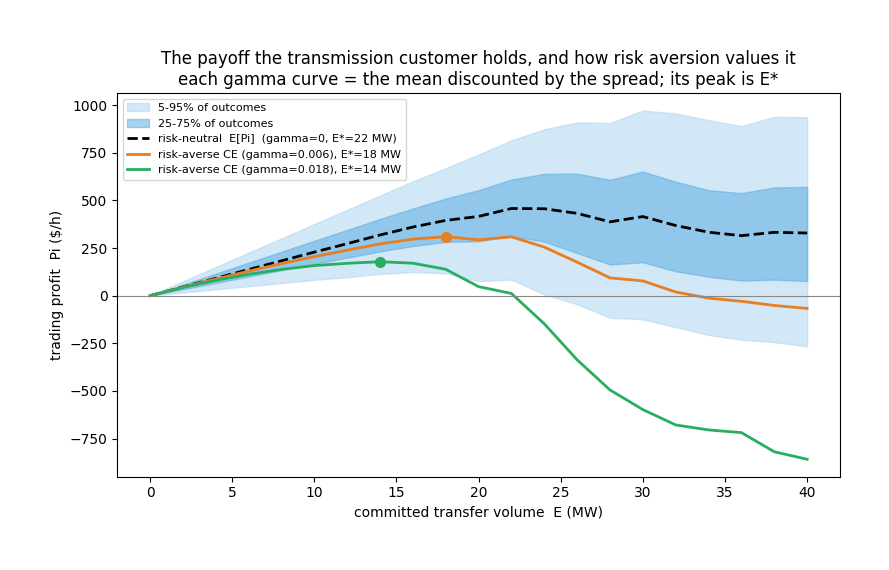

In [15]:
# The payoff fan and how risk aversion sizes the committed E.
GAMMA_COLORS = ['#2E86C1', '#E67E22', '#27AE60']
mean_pi = payoff.mean(axis=1)
var_pi  = payoff.var(axis=1)
qs = {p: np.percentile(payoff, p, axis=1) for p in (5, 25, 75, 95)}
fig, ax = plt.subplots(figsize=(8.2, 5))
ax.fill_between(E_grid, qs[5], qs[95], color='#AED6F1', alpha=0.55, label='5-95% of outcomes')
ax.fill_between(E_grid, qs[25], qs[75], color='#5DADE2', alpha=0.55, label='25-75% of outcomes')
Estar0 = E_grid[int(np.argmax(mean_pi))]
ax.plot(E_grid, mean_pi, 'k--', lw=2, label=f'risk-neutral  E[Pi]  (gamma=0, E*={Estar0:.0f} MW)')
for g, col in zip(GAMMAS, GAMMA_COLORS):
    if g == 0:
        continue
    ce = mean_pi - 0.5 * g * var_pi
    Estar = E_grid[int(np.argmax(ce))]
    ax.plot(E_grid, ce, color=col, lw=2, label=f'risk-averse CE (gamma={g}), E*={Estar:.0f} MW')
    ax.plot(Estar, ce.max(), 'o', color=col, ms=7)
ax.axhline(0, color='#888', lw=0.8)
ax.set_xlabel('committed transfer volume  E (MW)'); ax.set_ylabel('trading profit  Pi ($/h)')
ax.set_title('The payoff the transmission customer holds, and how risk aversion values it\n'
             'each gamma curve = the mean discounted by the spread; its peak is E*')
ax.legend(fontsize=8, loc='upper left'); plt.tight_layout(); plt.show()

The transfer right is worth $\mu_T \approx \$23$/MWh on average. The megawatts are
wheeled across BA-B, and as the committed $E$ grows the delivery loads BA-B's path
lines, so the real-time basis the customer pays rises and the distribution of outcomes
widens. A risk-neutral customer pushes $E$ toward the node-3 surplus. Raising risk
aversion $\gamma$ discounts the wider distribution and lowers the optimal commitment
$E^*$. The customer therefore facilitates a smaller transfer than the expected margin
alone would justify.

## 5. The parallel timing problem

The customer never controls a single transfer volume. Market A and Market B run their
bid windows in parallel, so the megawatts the customer self-schedules into Market B are
committed before it learns how much of the transfer Market A clears. There are three
distinct quantities, and the customer sets only two of them: the cap $\bar E$ it posts
to Market A, and the day-ahead self-schedule $E_B$ it posts to Market B. The cleared
transfer $E_A$ is an **endogenous** outcome of Market A's prices.

**The setup, in one place (standalone).** The transmission customer is the **importing
balancing authority** of Market A: BA-A1, at the pricey sink (bus 2). It sponsors
("donates") the transfer of cheap power from the source BA (BA-A2, bus 3) and, under the
base-case rules, collects its half of the Market A transfer rent. To take delivery it is
a transmission customer of Market B, which physically wheels the flow, so it
**self-schedules** the wheel there. The two day-ahead markets clear in parallel windows
and Market B re-clears in real time, so the customer fixes its Market B schedule *before*
it learns how much transfer Market A clears.

**Variables.**

*Transfer (quantity) variables*: $\bar E$ (the cap it posts to Market A, an **input**),
$E_B$ (the volume it self-schedules in Market B day-ahead, an **input** committed before
Market A clears), $E_A$ (the transfer Market A actually clears, $0 \le E_A \le \bar E$,
**endogenous**, revealed only when Market A clears).

*Price (LMP) variables*: $\mu_T \equiv \lambda^A_k - \lambda^A_s$ (the Market A transfer
price, the spread between the two non-connected BAs); $\lambda^B_s, \lambda^B_k$ (Market B's
**day-ahead** LMPs at source/sink, day-ahead basis $b \equiv \lambda^B_k - \lambda^B_s$);
$\lambda^{B,\mathrm{rt}}_s, \lambda^{B,\mathrm{rt}}_k$ (Market B's **real-time** LMPs, basis
$b^{\mathrm{rt}} \equiv \lambda^{B,\mathrm{rt}}_k - \lambda^{B,\mathrm{rt}}_s$); $CR$ (the
day-ahead congestion revenue allocated back to the self-scheduler).

**Settlement -- three components.**

1. **Transfer revenue (Market A, its 50% share).** The transfer rent $R_T=\mu_T E_A$ is split
   equally between the two BAs, so the customer's **allocated share** is

   $$A_T \;=\; \tfrac12\,\mu_T\,E_A. \qquad (8)$$

*In words.* The customer's allocated share of the transfer rent, $A_T$, is one half of the transfer price $\mu_T$ times the cleared transfer $E_A$. That is the customer's 50% split of the full transfer rent $R_T=\mu_T E_A$.

   Its own generator sets the sink price at its marginal cost ($\lambda^A_k = c_k$), so it
   earns zero energy rent and this transfer share is pure profit.
2. **Day-ahead wheel (Market B).** The self-schedule injects $E_B$ at the source and withdraws
   it at the sink, paying the day-ahead basis, and is allocated $CR$:

   $$S^{\mathrm{DA}} \;=\; \lambda^B_s E_B - \lambda^B_k E_B + CR \;=\; CR - b\,E_B. \qquad (9)$$

*In words.* The day-ahead wheel settlement $S^{\mathrm{DA}}$ is the source price $\lambda^B_s$ times the self-scheduled volume $E_B$, less the sink price $\lambda^B_k$ times the same volume $E_B$, plus the returned congestion credit $CR$. Equivalently, $S^{\mathrm{DA}}$ is the credit $CR$ minus the day-ahead basis $b$ times the self-scheduled volume $E_B$.
3. **Real-time imbalance (Market B).** Only $E_B$ was scheduled but $E_A$ flows, so the
   mismatch $E_A - E_B$ settles at the real-time prices:

   $$S^{\mathrm{RT}} \;=\; -\,b^{\mathrm{rt}}\,(E_A - E_B). \qquad (10)$$

*In words.* The real-time imbalance settlement $S^{\mathrm{RT}}$ is minus the real-time basis $b^{\mathrm{rt}}$ times the mismatch $E_A-E_B$ between the cleared transfer $E_A$ and the day-ahead self-schedule $E_B$. Note that the volume never locked in the day-ahead resettles at the real-time spread.

**Payoff.**

$$\Pi \;=\; A_T + S^{\mathrm{DA}} + S^{\mathrm{RT}}
       \;=\; \underbrace{\tfrac12\,\mu_T\,E_A}_{\text{transfer share}}
        \;+\; \underbrace{\big(CR - b\,E_B\big)}_{\text{day-ahead wheel}}
        \;-\; \underbrace{b^{\mathrm{rt}}\,(E_A - E_B)}_{\text{real-time}}. \qquad (11)$$

*In words.* The customer's full payoff $\Pi$ is the sum of its three settlements: the transfer-rent share $A_T=\tfrac12\mu_T E_A$, the day-ahead wheel $S^{\mathrm{DA}}=CR-bE_B$, and the real-time imbalance $S^{\mathrm{RT}}=-b^{\mathrm{rt}}(E_A-E_B)$.

**The price risk, formally.** The customer fixes $(\bar E, E_B)$ at commitment. $\mu_T$, $E_A$,
the two bases, and $CR$ realize afterward, so $\Pi$ is a random variable carrying three
risks.

1. **Transfer-revenue risk.** $A_T = \tfrac12\,\mu_T E_A$ rides the endogenous clear: if a
   source generator turns pricey or short, the transfer falls out of merit ($\mu_T \to 0$) or
   short of the cap ($E_A < \bar E$), and the share shrinks toward zero.
2. **Revenue-adequacy risk.** $CR$ offsets the day-ahead wheel only if the path is
   revenue-adequate. Otherwise the customer eats the shortfall $b\,E_B - CR \ge 0$.
3. **Real-time timing risk.** The mismatch $E_A - E_B$ settles at $b^{\mathrm{rt}}$, an
   independent draw whose size and sign need not match the day-ahead basis. The day-ahead
   schedule does not hedge the mismatch. Only $E_B = E_A$ removes the mismatch, and
   $E_B = E_A$ is infeasible, since $E_A$ is unknown when $E_B$ is set.

With risk aversion $\gamma$ the customer chooses
$\max_{\bar E,\,E_B}\ \mathbb{E}[\Pi] - \tfrac{\gamma}{2}\operatorname{Var}[\Pi]$.

In [16]:
# Shared Section-5 ledger. The importing-BA transmission customer's settlement, by MARKET AREA
# and PERIOD: it banks its 50% share of the Market A transfer rent (pure profit, since its
# generator earns LMP = cost) and settles the Market B wheel day-ahead plus the real-time
# deviation on the volume it could not lock. The SAME function renders the headline below, the
# per-case ledgers in the four-views cell, and the sandbox -- so every Section-5 ledger matches.
def s5_ledger(eA, eB, laA3, laA2, laB3, laB2, laBrt3, laBrt2, cr_return=1.0):
    muT_ = laA2 - laA3; b_ = laB2 - laB3; brt_ = laBrt2 - laBrt3; dev = eA - eB
    BL = ''
    rows = [
        ('Market A . day-ahead   transfer (50%)', BL, eA, laA3,   laA2,   muT_, eA,  0.5 * muT_ * eA),
        ('Market B . day-ahead   wheel',          eB, BL, laB3,   laB2,   b_,   eB,  -b_ * eB),
        ('Market B . day-ahead   CR credit',      eB, BL, BL,     BL,     b_,   eB,  +cr_return * b_ * eB),
        ('Market B . real-time   deviation',      eB, eA, laBrt3, laBrt2, brt_, dev, -brt_ * dev),
    ]
    Rn = lambda v, d=0: v if v == BL else round(v, d)
    df = pd.DataFrame(
        [(r[0], Rn(r[1]), Rn(r[2]), Rn(r[3], 1), Rn(r[4], 1), Rn(r[5], 1), Rn(r[6]), round(r[7], 1)) for r in rows],
        columns=['settlement (area . period)', 'E_B', 'E_A', 'lambda_3 (src)', 'lambda_2 (snk)',
                 'spread (l2-l3)', 'settled MW', '$/h']).set_index('settlement (area . period)')
    pi = sum(r[7] for r in rows)
    df.loc['Net to the transmission customer'] = [BL, BL, BL, BL, BL, BL, round(pi, 1)]
    return df, pi

EA           = E                                   # Market A clears the cap: E_A = Ebar (the matched volume)
laA_s, laA_k = rA.lmp[SOURCE], rA.lmp[SINK]        # Market A LMPs at src/sink (the transfer spread mu_T)
laB_s, laB_k = rB.lmp[SOURCE], rB.lmp[SINK]        # Market B day-ahead LMPs at src/sink (the wheel)
basis_B      = laB_k - laB_s

# -- EDIT -- the fraction of the day-ahead basis the path's congestion revenue returns.
CR_RETURN = 1.0     # 1.0 = revenue-adequate (CR credit fully offsets the wheel); < 1.0 = underfunded (a risk)

# Real-time basis: two actual clears bracket it (the delivery congests BA-B, or it does not).
rB_rt_c = solve_engine_dispatch(pt9, engB, exo={SOURCE: +EA, SINK: -EA}, shed_price=150.0)
rB_rt_r = solve_engine_dispatch(pt9, engB, exo=None, shed_price=150.0)
basis_rt = {'RT congests': rB_rt_c.lmp[SINK] - rB_rt_c.lmp[SOURCE],
            'RT relieves': rB_rt_r.lmp[SINK] - rB_rt_r.lmp[SOURCE]}

# Headline: the customer UNDER-schedules (E_B < E_A) and real time congests.
EB_h = 20.0
led, pi_h = s5_ledger(EA, EB_h, laA_s, laA_k, laB_s, laB_k, rB_rt_c.lmp[SOURCE], rB_rt_c.lmp[SINK], CR_RETURN)
display(led)
print('Reading it: transfer row = the 50% share = 0.5 x spread x settled MW (pure profit, the generator earns LMP=cost);')
print('wheel / CR credit / deviation = -/+ spread x settled MW   (CR returns the basis only if the path is revenue-adequate).')

# Pi for the three schedules the customer can actually reach, x the real-time outcome.
# E_B can NEVER exceed the posted cap Ebar, so the only way E_B > E_A is the transfer
# CLEARING SHORT of the cap (a Market A generator change) -- the third case below, NOT a
# self-schedule above the cap.
flt_short = {k: (dict(v) if v['bus'] != SOURCE else {**v, 'p_nom': v['p_nom'] - 20.0})
             for k, v in GEN_FLEET.items()}
engA_short = wm.make_engine('Market A', MKT_DEFS['Market A'], gen_fleet=flt_short, loads=LOADS, activated=[])
rA_short   = solve_engine_transfers(pt9, engA_short, A_AREAS, {A_IFC: EBAR})
EA_short, muT_short = abs(rA_short.transfers[A_IFC]), abs(rA_short.transfer_duals[A_IFC])

def _pi(eA_, eB_, mt, brt):
    return 0.5 * mt * eA_ + (CR_RETURN * basis_B * eB_ - basis_B * eB_) - brt * (eA_ - eB_)
scen = [('matched       E_B = E_A = Ebar', EA,       EA,   muT),
        ('under-sched   E_B < E_A = Ebar', EA,       20.0, muT),
        ('clears short  E_A < E_B = Ebar', EA_short, EBAR, muT_short)]
grid = pd.DataFrame(
    [{'Ebar': EBAR, 'E_A': round(eA_, 0), 'E_B': round(eB_, 0), 'E_A-E_B': round(eA_ - eB_, 0),
      'Pi | RT congests': round(_pi(eA_, eB_, mt, basis_rt['RT congests']), 0),
      'Pi | RT relieves': round(_pi(eA_, eB_, mt, basis_rt['RT relieves']), 0)}
     for _, eA_, eB_, mt in scen], index=[s[0] for s in scen])
display(grid)
print(f'E_B is capped at Ebar={EBAR:.0f}, so it can only be <= the cleared E_A -- unless the transfer itself')
print(f'clears short (here E_A={EA_short:.0f} < Ebar via a Market A gen change, mu_T -> $0): the third case below.')
print(f'matched banks the full ${0.5 * muT * EA:,.0f} transfer share in either real-time outcome; any mismatch bets')
print('the real-time basis (' + '   '.join(f'{k}: basis_rt=${v:.0f}' for k, v in basis_rt.items()) + ').')

,E_B,E_A,lambda_3 (src),lambda_2 (snk),spread (l2-l3),settled MW,$/h
settlement (area . period),,,,,,,
Market A . day-ahead transfer (50%),,30.0,25.0,48.0,23.0,30.0,345.0
Market B . day-ahead wheel,20.0,,20.0,35.0,15.0,20.0,-300.0
Market B . day-ahead CR credit,20.0,,,,15.0,20.0,300.0
Market B . real-time deviation,20.0,30.0,20.0,35.0,15.0,10.0,-150.0
Net to the transmission customer,,,,,,,195.0


Reading it: transfer row = the 50% share = 0.5 x spread x settled MW (pure profit, the generator earns LMP=cost);

wheel / CR credit / deviation = -/+ spread x settled MW   (CR returns the basis only if the path is revenue-adequate).

,Ebar,E_A,E_B,E_A-E_B,Pi | RT congests,Pi | RT relieves
matched E_B = E_A = Ebar,30.0,30.0,30.0,0.0,345.0,345.0
under-sched E_B < E_A = Ebar,30.0,30.0,20.0,10.0,195.0,345.0
clears short E_A < E_B = Ebar,30.0,20.0,30.0,-10.0,150.0,0.0


E_B is capped at Ebar=30, so it can only be <= the cleared E_A -- unless the transfer itself

clears short (here E_A=20 < Ebar via a Market A gen change, mu_T -> $0): the third case below.

matched banks the full $345 transfer share in either real-time outcome; any mismatch bets

the real-time basis (RT congests: basis_rt=$15   RT relieves: basis_rt=$0).

### The same mismatch on the network -- four views per case

The table prices the mismatch and the network figures show it. $E_A$ is endogenous,
whatever Market A clears against the cap given its generators, while $E_B$ is the input
day-ahead self-schedule. Each case below carries the four views of Section 2:
**Market A** (the transfer Market A clears, $E_A$), **Market B** (the room Market B
reserves for the self-schedule $E_B$), **Combined** (the one line carrying the actual
transfer $E_A$ against that reserved room), and **Unified** (the secure benchmark).
There are three cases:

- **Matched** $(E_B = E_A)$: the self-schedule equals the cleared transfer; the
  Combined line is secure.
- **Under-scheduled** $(E_B < E_A)$: the customer self-scheduled less than Market A
  cleared, so Market B reserved too little room and the transfer overloads its path. The
  shortfall $E_A - E_B$ resettles in real time.
- **Transfer clears short of cap** $(E_A < \bar E)$: a Market A generator becomes
  pricier or less available, so the *endogenous* transfer falls below the posted cap.
  The customer had self-scheduled to the cap $(E_B = \bar E)$, so now $E_B > E_A$ and
  Market B has over-reserved and counter-flows.

Each inset shows the transfer Market A cleared ($E_A$, the flow) against the cap the
customer posted ($\bar E$, the limit). The transfer is reduced by lowering $\bar E$ or
by a move in the merit order. It is never reduced by under-scheduling $E_A$, because
$E_A$ is not the customer's to set.

=== MATCHED  (E_B = E_A) : settlement ledger (real-time congested; the importing-BA generator earns LMP=cost) ===

,E_B,E_A,lambda_3 (src),lambda_2 (snk),spread (l2-l3),settled MW,$/h
settlement (area . period),,,,,,,
Market A . day-ahead transfer (50%),,30.0,25.0,48.0,23.0,30.0,345.0
Market B . day-ahead wheel,30.0,,20.0,35.0,15.0,30.0,-450.0
Market B . day-ahead CR credit,30.0,,,,15.0,30.0,450.0
Market B . real-time deviation,30.0,30.0,20.0,35.0,15.0,0.0,-0.0
Net to the transmission customer,,,,,,,345.0


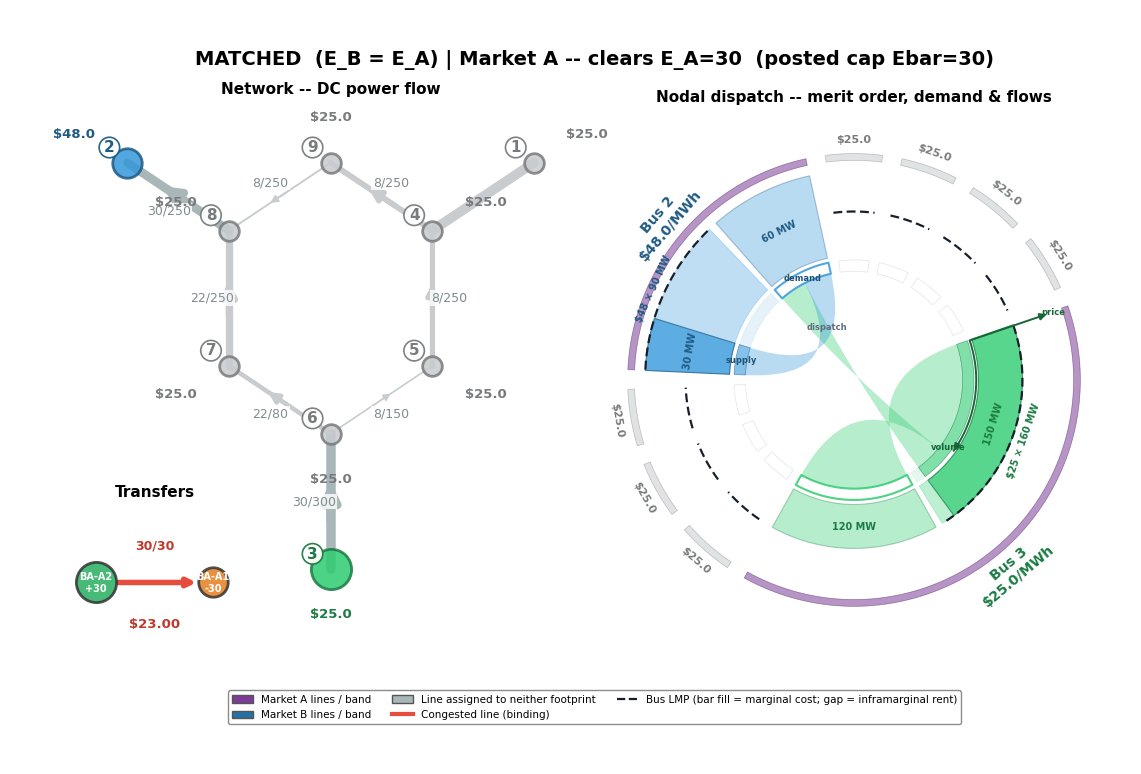

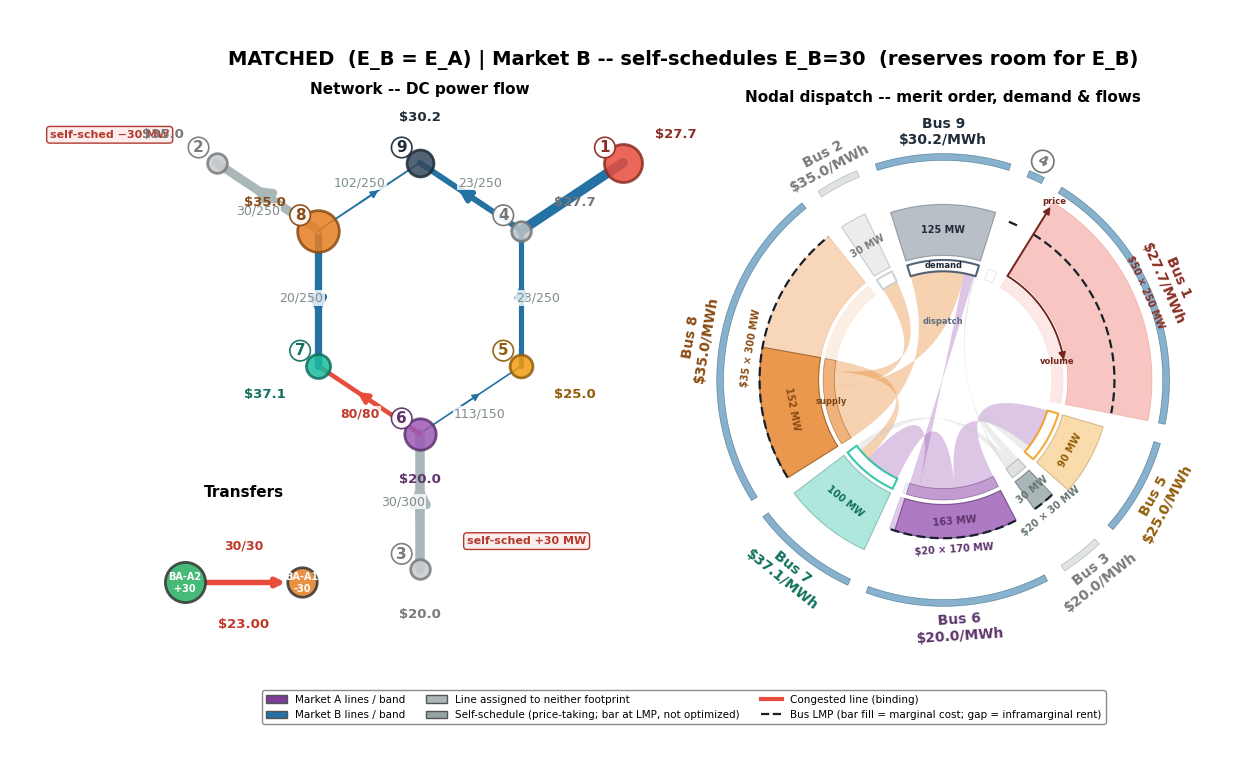

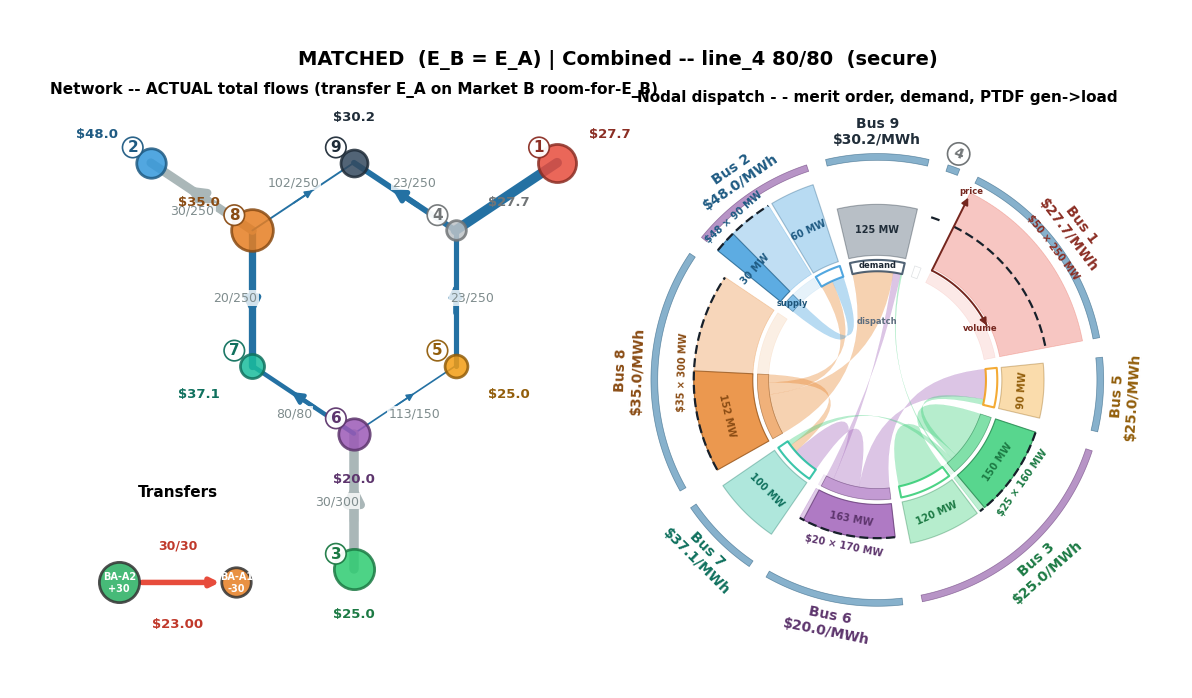

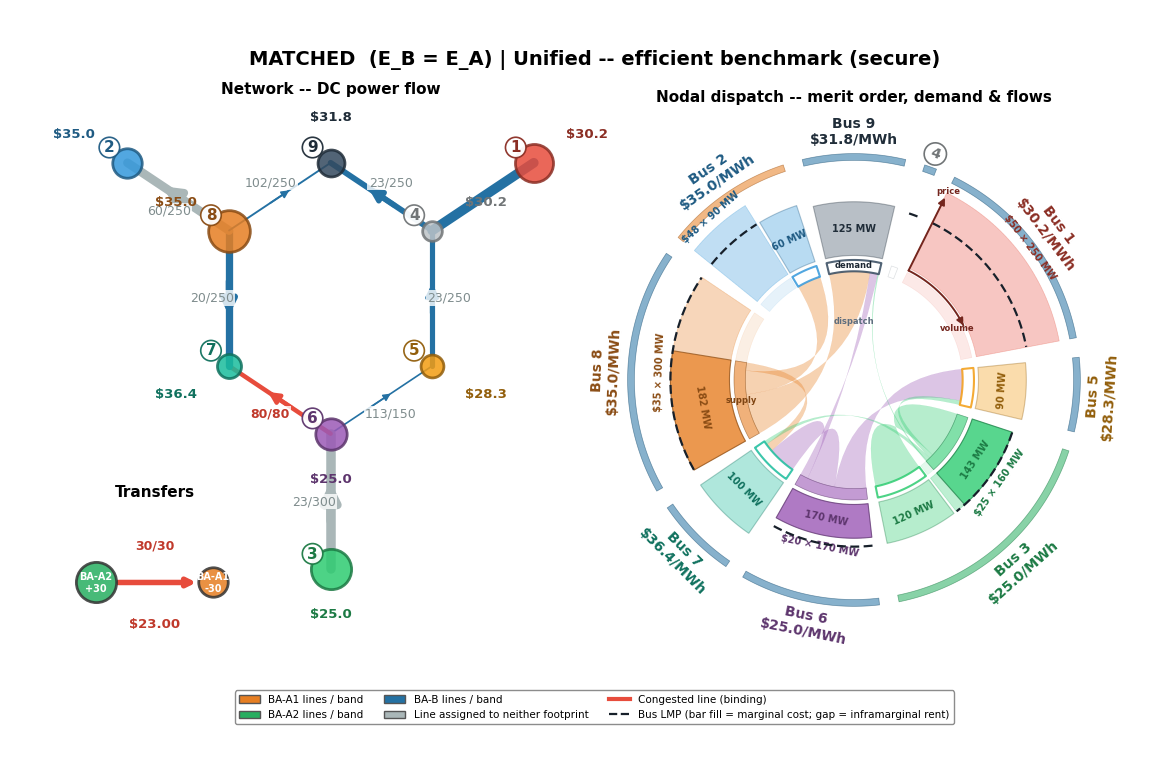

MATCHED  (E_B = E_A)                                           E_A=30  E_B=30  mu_T=$23  line_4=80.0/80  secure

=== UNDER-SCHEDULED  (E_B < E_A) : settlement ledger (real-time congested; the importing-BA generator earns LMP=cost) ===

,E_B,E_A,lambda_3 (src),lambda_2 (snk),spread (l2-l3),settled MW,$/h
settlement (area . period),,,,,,,
Market A . day-ahead transfer (50%),,30.0,25.0,48.0,23.0,30.0,345.0
Market B . day-ahead wheel,20.0,,35.0,35.0,0.0,20.0,-0.0
Market B . day-ahead CR credit,20.0,,,,0.0,20.0,0.0
Market B . real-time deviation,20.0,30.0,20.0,35.0,15.0,10.0,-150.0
Net to the transmission customer,,,,,,,195.0


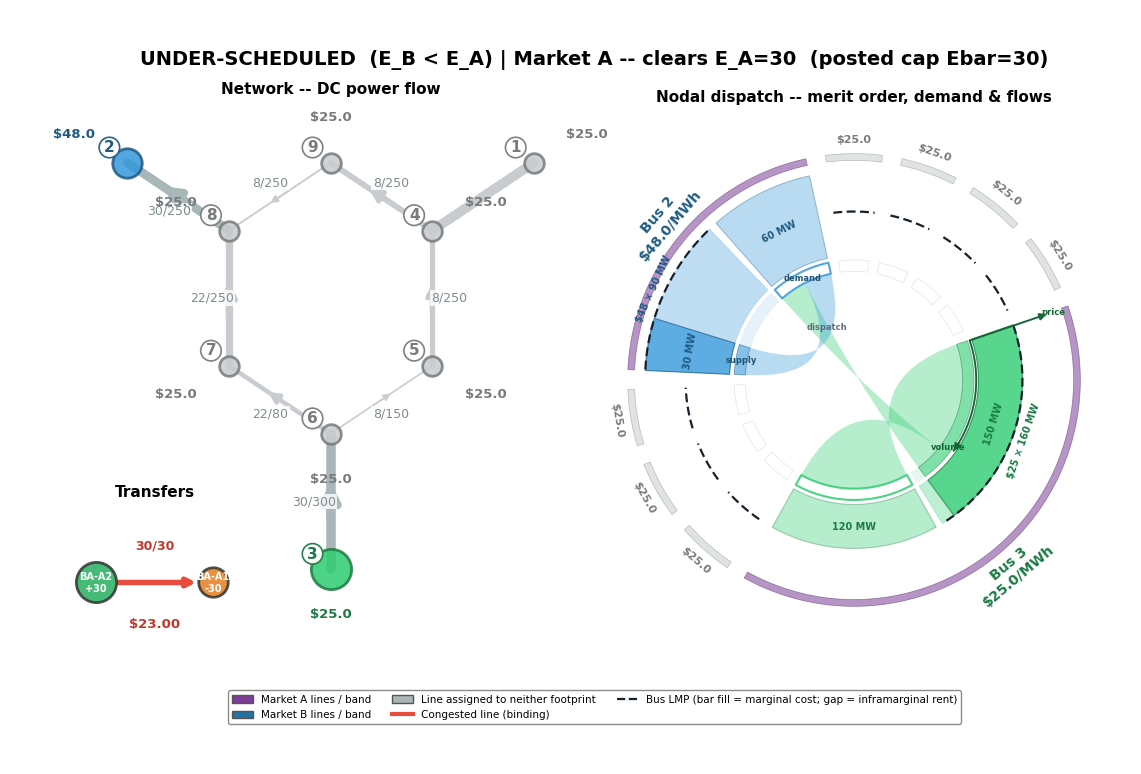

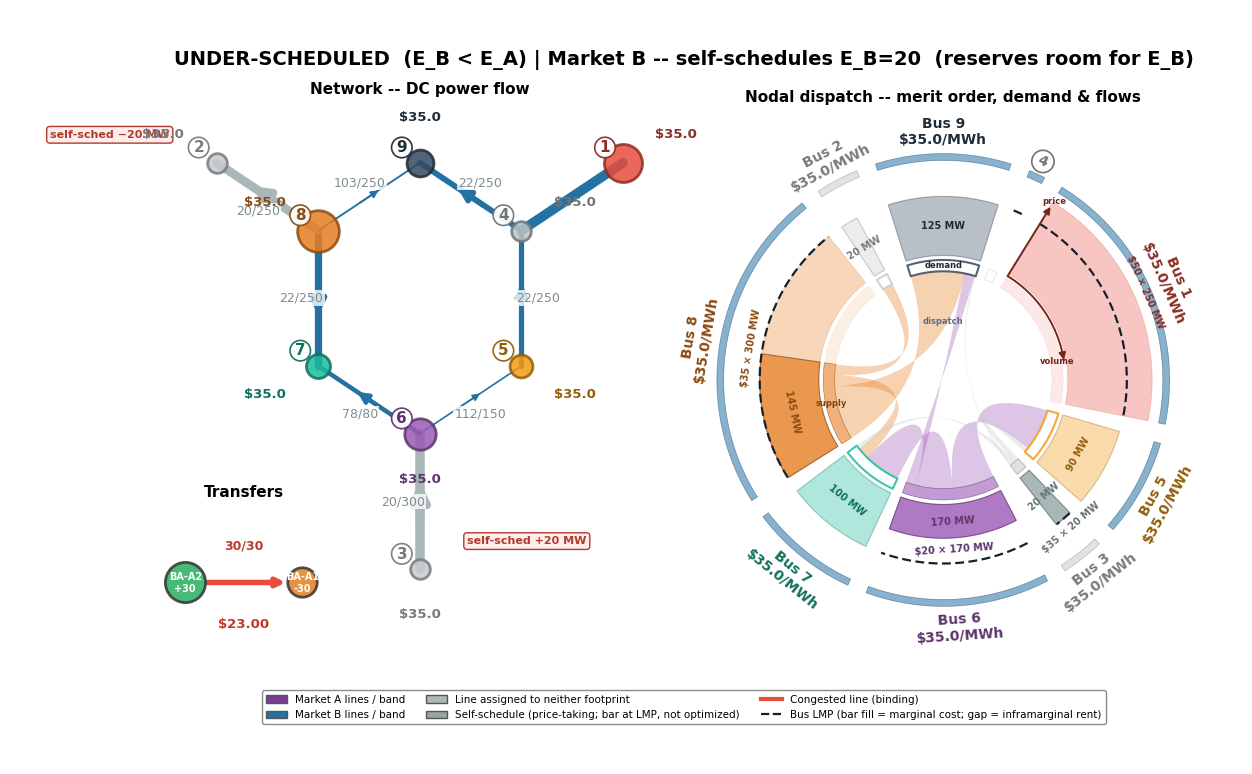

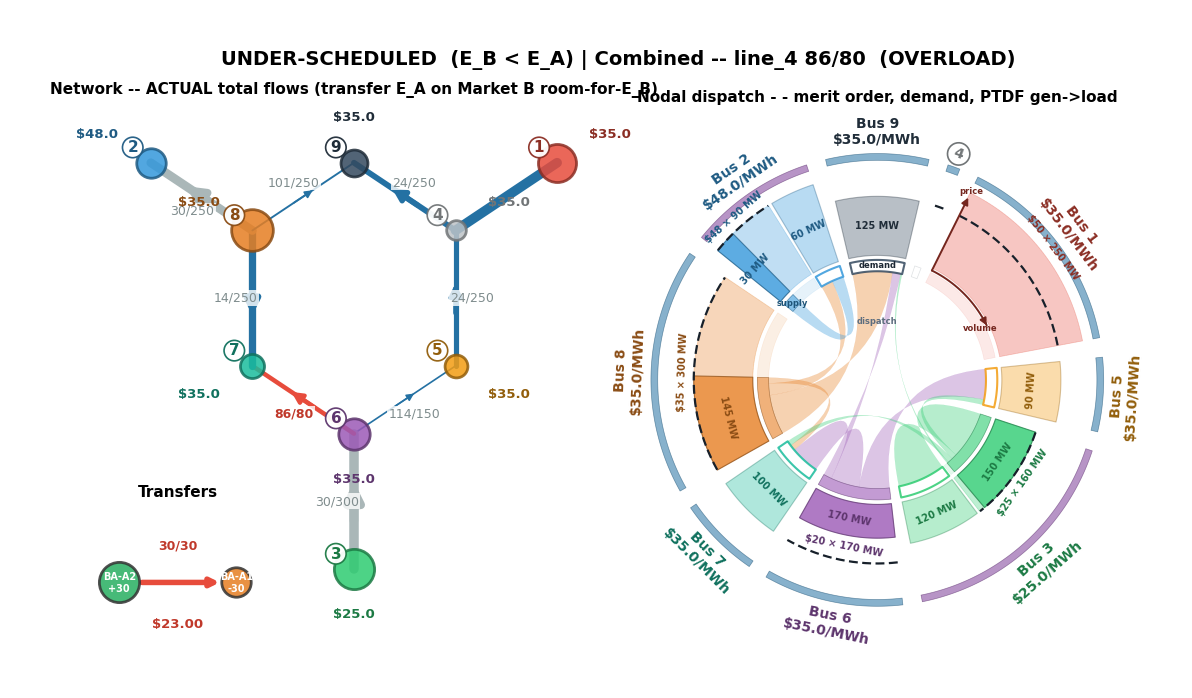

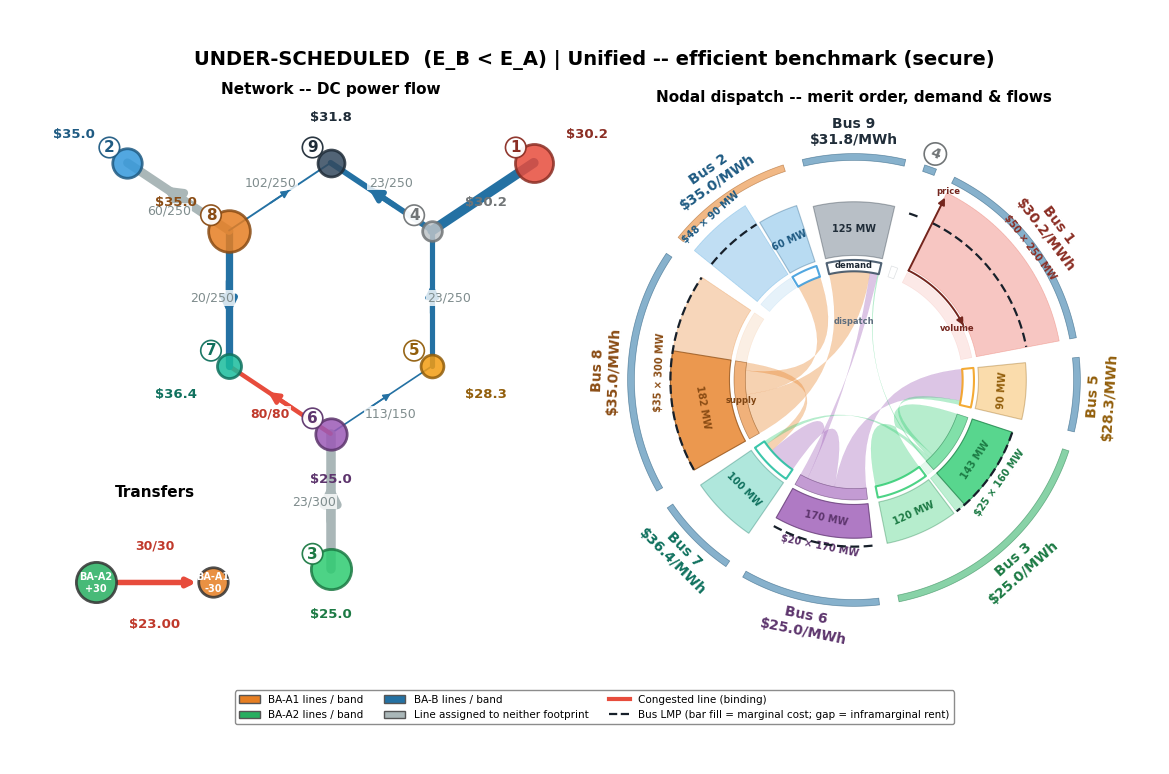

UNDER-SCHEDULED  (E_B < E_A)                                   E_A=30  E_B=20  mu_T=$23  line_4=85.6/80  OVERLOAD

=== TRANSFER CLEARS SHORT OF CAP  (gen change -> E_A < E_B = Ebar) : settlement ledger (real-time congested; the importing-BA generator earns LMP=cost) ===

,E_B,E_A,lambda_3 (src),lambda_2 (snk),spread (l2-l3),settled MW,$/h
settlement (area . period),,,,,,,
Market A . day-ahead transfer (50%),,20.0,48.0,48.0,0.0,20.0,0.0
Market B . day-ahead wheel,30.0,,20.0,35.0,15.0,30.0,-450.0
Market B . day-ahead CR credit,30.0,,,,15.0,30.0,450.0
Market B . real-time deviation,30.0,20.0,20.0,35.0,15.0,-10.0,150.0
Net to the transmission customer,,,,,,,150.0


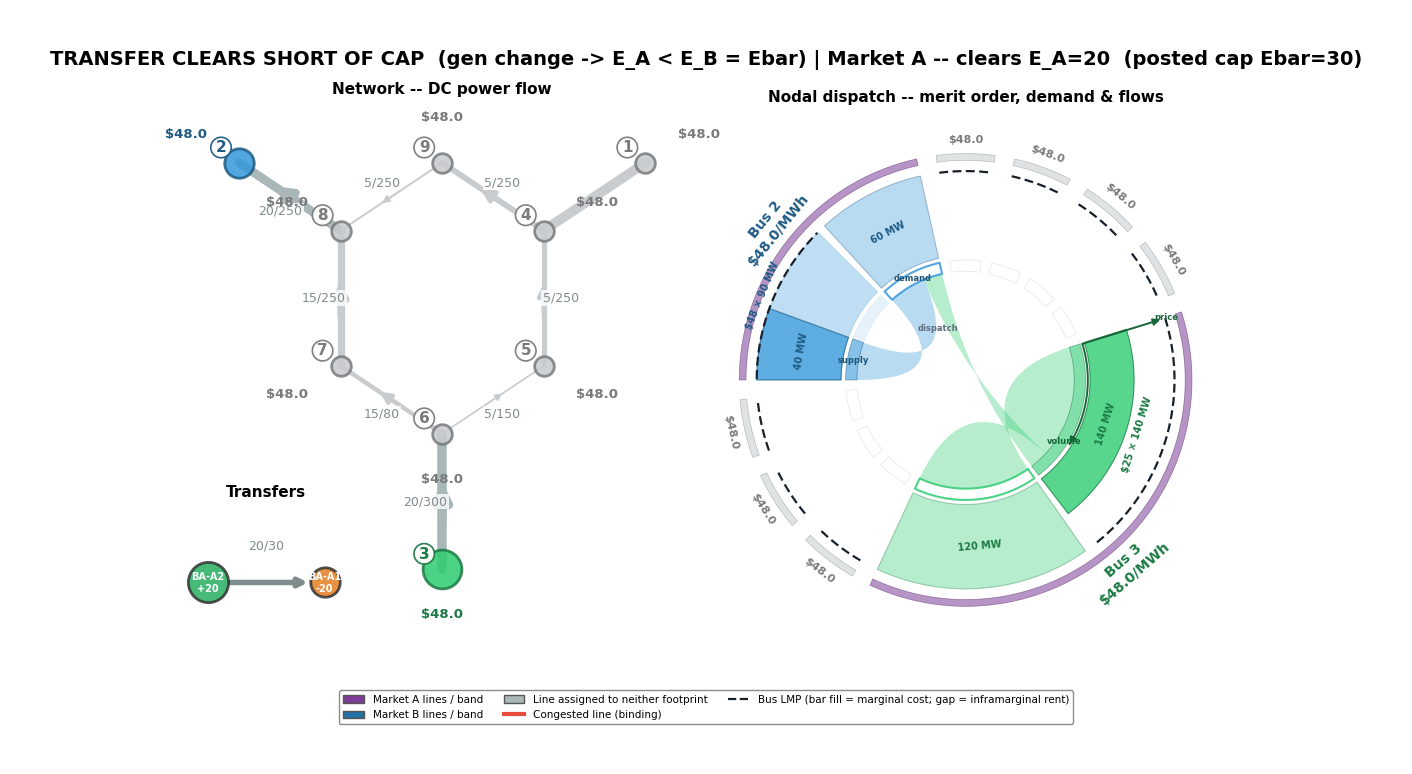

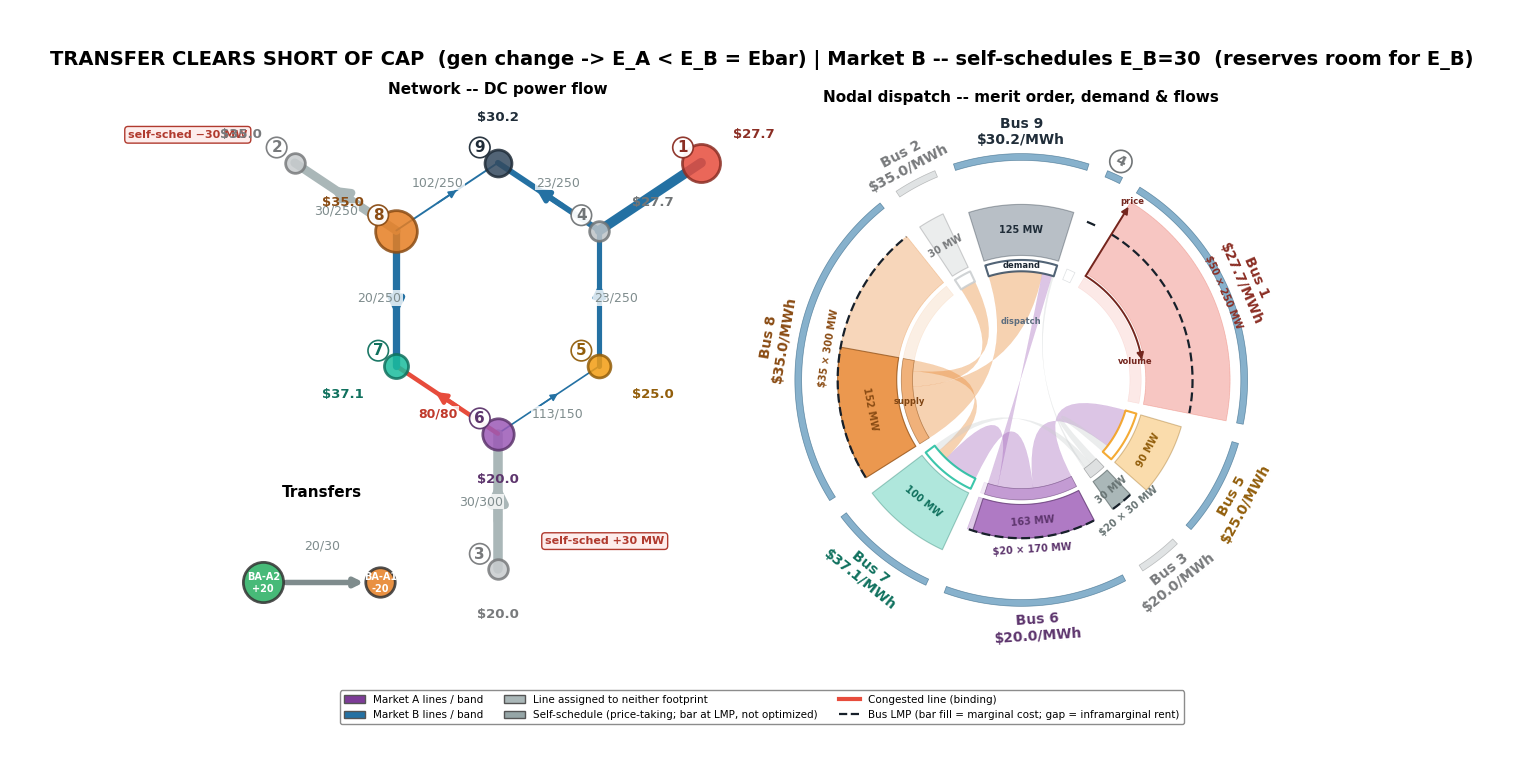

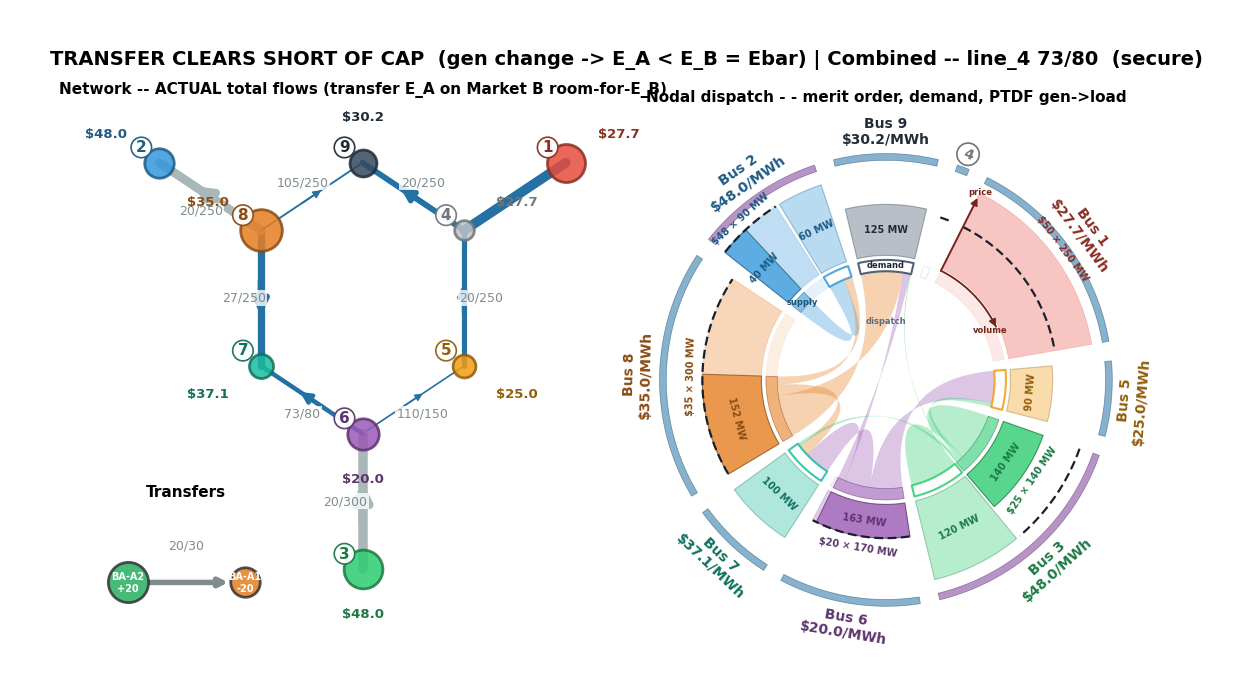

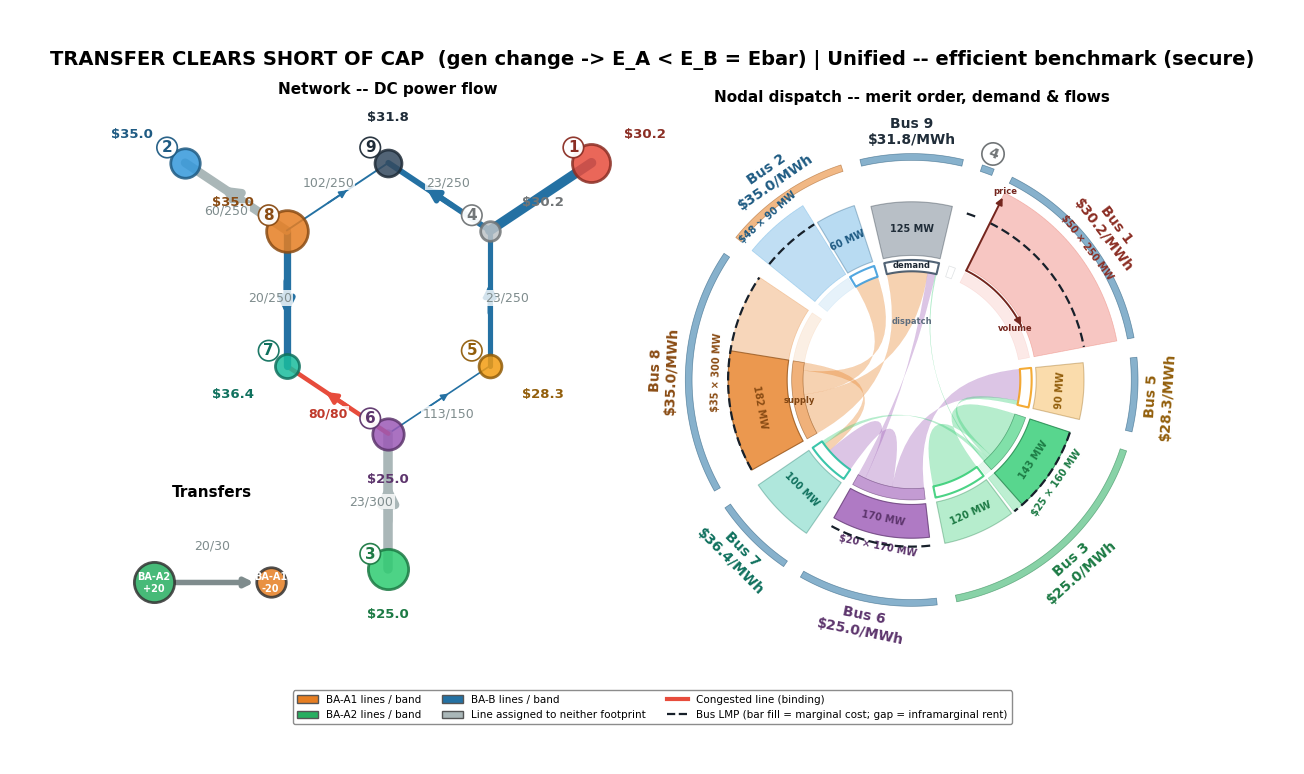

TRANSFER CLEARS SHORT OF CAP  (gen change -> E_A < E_B = Ebar) E_A=20  E_B=30  mu_T=$0  line_4=72.5/80  secure

In [17]:
# Render the four Section-2 views for one case. E_A is ENDOGENOUS: Market A clears the cap
# Ebar against the (possibly altered) Market A generators, and E_A is whatever comes out.
def mismatch_case(gen_fleet_A, ebar_, eB_, tag):
    engA_ = wm.make_engine('Market A', MKT_DEFS['Market A'], gen_fleet=gen_fleet_A, loads=LOADS, activated=[])
    rA_   = solve_engine_transfers(pt9, engA_, A_AREAS, {A_IFC: ebar_})      # E_A endogenous, <= Ebar
    muT_  = abs(rA_.transfer_duals[A_IFC]); eA = abs(rA_.transfers[A_IFC])
    rB_   = solve_engine_dispatch(pt9, engB,                                 # Market B reserves room for E_B
                                  exo=({SOURCE: +eB_, SINK: -eB_} if eB_ > 1e-6 else None), shed_price=150.0)
    # -- per-case settlement ledger (shared Section-5 s5_ledger format) --
    print(f'=== {tag} : settlement ledger (real-time congested; the importing-BA generator earns LMP=cost) ===')
    _ledc, _ = s5_ledger(eA, eB_, rA_.lmp[SOURCE], rA_.lmp[SINK],
                         rB_.lmp[SOURCE], rB_.lmp[SINK],
                         rB_rt_c.lmp[SOURCE], rB_rt_c.lmp[SINK], CR_RETURN)
    display(_ledc)

    def _ins(fig):                                                          # inset: flow E_A vs posted cap Ebar
        figs.transfer_inset(fig.add_axes(figs.INSET_RECT), INS_LABELS, INS_TAM,
                            {'BA-A2': +eA, 'BA-A1': -eA}, eA, ebar_, muT_, INS_COLORS, INS_TIECAP)

    fA = figs.footprint_figure(net9, pt9, fp_mkt, engA_, rA_, highlight='Market A', bus_colors=BUS_COLORS_3BA,
                               suptitle=f'{tag} | Market A -- clears E_A={eA:.0f}  (posted cap Ebar={ebar_:.0f})')
    _ins(fA); plt.show()
    fB = figs.footprint_figure(net9, pt9, fp_mkt, engB, rB_, highlight='Market B', bus_colors=BUS_COLORS_3BA,
                               exo_sched=({SOURCE: +eB_, SINK: -eB_} if eB_ > 1e-6 else None),
                               suptitle=f'{tag} | Market B -- self-schedules E_B={eB_:.0f}  (reserves room for E_B)')
    _ins(fB); plt.show()

    p_ = np.zeros(pt9.n_bus)                                                # Combined: actual total flows
    for r_ in (rA_, rB_):
        for b, mw in r_.gen_by_bus.items():  p_[pt9.bus_idx[b]] += mw
        for b, mw in r_.load_by_bus.items(): p_[pt9.bus_idx[b]] -= mw
    f_ = pt9.ptdf @ p_
    over_ = {l for l, x in zip(pt9.lines, f_) if abs(x) > pt9.s_nom[pt9.line_idx[l]] + 1e-6}
    l4, rate4 = float(f_[pt9.line_idx['line_4']]), pt9.s_nom[pt9.line_idx['line_4']]
    host_ = {b: (rA_.lmp[b] if b in MKT_DEFS['Market A'] else rB_.lmp[b]) for b in pt9.buses}
    sup_, dem_ = {}, {}
    for e_, r_ in ((engA_, rA_), (engB, rB_)):
        s_, d_ = to_supply_demand(e_, r_); sup_.update(s_); dem_.update(d_)
    figC, _ = plot_combined_letter(
        net9, sup_, dem_, bus_colors=BUS_COLORS_3BA, bus_lmps=host_,
        line_flows={l: float(x) for l, x in zip(pt9.lines, f_)},
        line_widths=susceptance_widths(pt9), line_colors=fp_mkt.line_colors(pt9),
        constrained_lines=over_, flows=nodal_plot.compute_ptdf_flows(net9, sup_, dem_),
        lmp_line=True, bus_groups=fp_mkt.groups(pt9), group_colors=dict(MKT_COLORS), show_group_labels=False,
        all_buses=pt9.buses, sector_order=RING_ORDER, bus_coords=COORDS, center_bus=CENTER_BUS,
        annotate_roles=True, axis_key=True,
        title_left='Network -- ACTUAL total flows (transfer E_A on Market B room-for-E_B)',
        suptitle=f'{tag} | Combined -- line_4 {abs(l4):.0f}/{rate4:.0f}  ({"OVERLOAD" if over_ else "secure"})')
    _ins(figC); plt.show()

    fU = figs.footprint_figure(net9, pt9, fp_ba, unified, resU, bus_colors=BUS_COLORS_3BA,
                               suptitle=f'{tag} | Unified -- efficient benchmark (secure)')
    _ins(fU); plt.show()
    return eA, muT_, abs(l4), bool(over_)

# Case 3 alters a Market A generator so the ENDOGENOUS transfer falls short of the cap:
# cut node-3 (the cheap exporter) availability so its exportable surplus < Ebar.
FLEET_A_SHORT = {k: (dict(v) if v['bus'] != SOURCE else {**v, 'p_nom': v['p_nom'] - 20.0})
                 for k, v in GEN_FLEET.items()}

# -- EDIT -- (Market A generators, Ebar posted, E_B self-scheduled in day-ahead)
MISMATCH_CASES = [
    (GEN_FLEET,     30.0, 30.0, 'MATCHED  (E_B = E_A)'),
    (GEN_FLEET,     30.0, 20.0, 'UNDER-SCHEDULED  (E_B < E_A)'),
    (FLEET_A_SHORT, 30.0, 30.0, 'TRANSFER CLEARS SHORT OF CAP  (gen change -> E_A < E_B = Ebar)'),
]
for _flt, _ebar, _eB, _tag in MISMATCH_CASES:
    _e, _m, _l4, _ov = mismatch_case(_flt, _ebar, _eB, _tag)
    print(f'{_tag:62s} E_A={_e:.0f}  E_B={_eB:.0f}  mu_T=${_m:.0f}  line_4={_l4:.1f}/80  '
          f'{"OVERLOAD" if _ov else "secure"}')

The customer is the importing BA. It collects its half of the transfer rent,
$\tfrac12\,\mu_T E_A$, and because its own generator sets the sink price at cost that half
is pure profit, \$345/h when the transfer clears the full cap. That profit is at risk three
ways, and the per-case ledgers below show the three components adding up. Its size rides
the endogenous clear. When a source generator falls short, the transfer underclears or
drops out of merit ($\mu_T \to 0$) and the share collapses, as in the transfer-clears-short
case, where the customer banks $0$. The day-ahead wheel is a wash only if the path is
revenue-adequate. The volume the customer could not lock, $E_A - E_B$, resettles at the
real-time basis, in either sign and with no day-ahead hedge. The path overloads at line_4
85.6/80 when the customer under-schedules and is slack at 72.5/80 when the transfer clears
short. Matching $E_B = E_A$ on a revenue-adequate, in-merit transfer is the only case in
which the customer banks the full \$345.

## 6. Sandbox -- vary the inputs, watch the settlement

Everything above runs off a handful of inputs. The editable inputs are the generators
(cost and capacity per node), the loads, the day-ahead self-schedule $E_B$, the transfer
cap $\bar E$, and the line limits. The real-time generators and loads are set
separately, so the real-time prices can differ from the day-ahead prices. The cleared
transfer $E_A$ is endogenous, Market A's outcome against the cap, so it is never set
directly. $E_A$ moves when $\bar E$ or the Market A generators change. The sandbox
reports the transaction from the transmission customer's view (day-ahead transfer rent,
congestion-neutral wheel, real-time resettlement of $E_A - E_B$), tabulates each
market's production cost, generation and load and each BA's load and generation
payments, and draws the four network views, which show when the self-schedule and the
limits drive the path line into overload.

In [18]:
# ============================ SANDBOX -- EDIT HERE ============================
# Generators {node: (marginal cost $/MWh, capacity MW)}.  Market A = nodes SRC, SNK.
SB_GENS_DA  = {'1': (50, 250), '2': (48, 90), '3': (25, 160), '6': (20, 170), '8': (35, 300)}
SB_LOADS_DA = {'2': 60, '3': 120, '5': 90, '7': 100, '9': 125}
# Real time differs from day-ahead?  Override only the nodes that change (else inherit DA).
SB_GENS_RT  = {}          # e.g. {'6': (20, 120)}  a Market B unit less available in real time
SB_LOADS_RT = {}          # e.g. {'7': 130}        higher real-time load
SB_EB       = 60.0        # day-ahead self-schedule in Market B (exogenous input)
SB_EBAR     = 30.0        # transfer cap posted to Market A (input)
SB_LIMITS   = {'line_4': 80.0}   # transmission limits {line: MW}
SB_SRC, SB_SNK = '3', '2'        # transfer source (cheap) -> sink (pricey); Market A = {SRC, SNK}
# =============================================================================
def _fleet(spec): return {f'g{n}': {'bus': n, 'cost': c, 'p_nom': p} for n, (c, p) in spec.items()}
gens_da = _fleet(SB_GENS_DA)
gens_rt = _fleet({**SB_GENS_DA, **SB_GENS_RT})
loads_rt = {**SB_LOADS_DA, **SB_LOADS_RT}
net_sb = wm.build_network(SB_LIMITS); pt_sb = compute_ptdf(net_sb, slack_bus='1')
MKT_SB = {'Market A': [SB_SNK, SB_SRC], 'Market B': [b for b in pt_sb.buses if b not in (SB_SNK, SB_SRC)]}
BA_SB  = {'BA-A1': [SB_SNK], 'BA-A2': [SB_SRC], 'BA-B': MKT_SB['Market B']}
costA_sb = ra.cost_by_bus(gens_da)

# Day-ahead: Market A clears the cap (E_A endogenous); Market B wheels the self-schedule E_B.
engA_sb = wm.make_engine('Market A', MKT_SB['Market A'], gen_fleet=gens_da, loads=SB_LOADS_DA, activated=[])
A_AREAS_SB = {'BA-A2': [SB_SRC], 'BA-A1': [SB_SNK]}; A_IFC_SB = tuple(sorted(A_AREAS_SB))
rA_sb   = solve_engine_transfers(pt_sb, engA_sb, A_AREAS_SB, {A_IFC_SB: SB_EBAR})
EA_sb   = abs(rA_sb.transfers[A_IFC_SB]); muT_sb = abs(rA_sb.transfer_duals[A_IFC_SB])
engB_sb = wm.make_engine('Market B', MKT_SB['Market B'], gen_fleet=gens_da, loads=SB_LOADS_DA)
rB_sb   = solve_engine_dispatch(pt_sb, engB_sb,
                                exo=({SB_SRC: +SB_EB, SB_SNK: -SB_EB} if SB_EB > 1e-6 else None), shed_price=150.0)
basis_da_sb = rB_sb.lmp[SB_SNK] - rB_sb.lmp[SB_SRC]
# Real time: re-clear Market B carrying the ACTUAL transfer E_A, with the real-time gens/loads.
engB_rt = wm.make_engine('Market B', MKT_SB['Market B'], gen_fleet=gens_rt, loads=loads_rt)
rB_rt_sb = solve_engine_dispatch(pt_sb, engB_rt,
                                 exo=({SB_SRC: +EA_sb, SB_SNK: -EA_sb} if EA_sb > 1e-6 else None), shed_price=150.0)
basis_rt_sb = rB_rt_sb.lmp[SB_SNK] - rB_rt_sb.lmp[SB_SRC]
# Unified reference.
engU_sb = wm.make_engine('UNIFIED', buses=pt_sb.buses, gen_fleet=gens_da, loads=SB_LOADS_DA)
rU_sb   = solve_engine_dispatch(pt_sb, engU_sb, shed_price=150.0)

print(f'Day-ahead  : E_A (endogenous) = {EA_sb:.0f} MW  (cap Ebar = {SB_EBAR:.0f})   mu_T = ${muT_sb:.0f}/MWh   '
      f'self-schedule E_B = {SB_EB:.0f} MW   basis_B(DA) = ${basis_da_sb:.0f}/MWh')
print(f'Real time  : basis_rt = ${basis_rt_sb:.0f}/MWh   mismatch E_A - E_B = {EA_sb - SB_EB:+.0f} MW')

INFO:ieee9_network:Imported IEEE 9-bus: 9 buses, 3 gens, 3 loads, 9 lines


Day-ahead  : E_A (endogenous) = 30 MW  (cap Ebar = 30)   mu_T = $23/MWh   self-schedule E_B = 60 MW   basis_B(DA) = $15/MWh

Real time  : basis_rt = $15/MWh   mismatch E_A - E_B = -30 MW

INFO:ieee9_network:Imported IEEE 9-bus: 9 buses, 3 gens, 3 loads, 9 lines


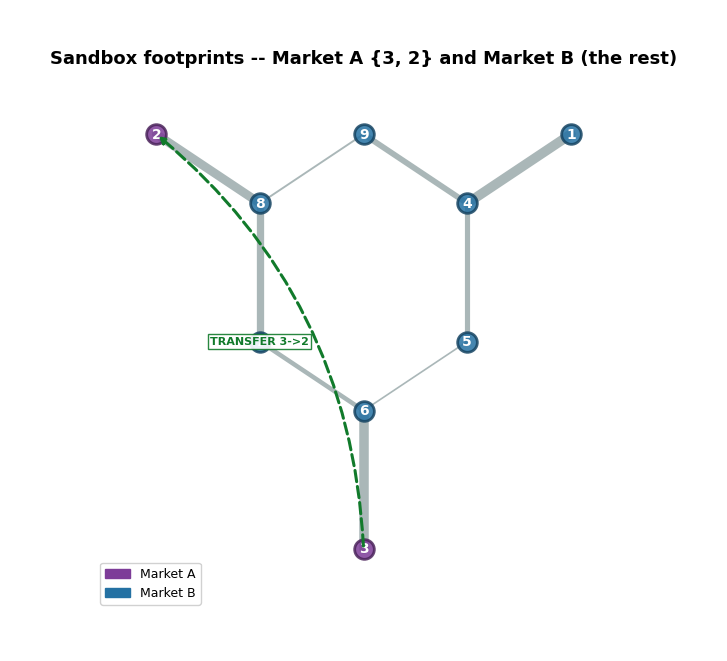

In [19]:
# Configuration map for the sandbox assignment (re-run after editing the knobs above).
import matplotlib.patches as mpatches
_fpm_sb = fpmod.make(pt_sb, MKT_SB, MKT_COLORS, tie_label='seam')
_bcol_sb = {b: MKT_COLORS[_fpm_sb.fp_of(b)] for b in pt_sb.buses}
fig, ax = plot_network_topology(
    build_network(SB_LIMITS), supply_by_bus={}, demand_by_bus={},
    bus_colors=_bcol_sb, bus_coords=COORDS,
    line_flows={l: 0.0 for l in pt_sb.lines}, line_widths=susceptance_widths(pt_sb),
    line_colors=_fpm_sb.line_colors(pt_sb),
    title=f'Sandbox footprints -- Market A {{{SB_SRC}, {SB_SNK}}} and Market B (the rest)')
ax.annotate('', xy=COORDS[SB_SNK], xytext=COORDS[SB_SRC],
            arrowprops=dict(arrowstyle='-|>', color='#117A2B', lw=2.2, ls='--',
                            connectionstyle='arc3,rad=0.22'), zorder=8)
_mx, _my = (COORDS[SB_SRC][0] + COORDS[SB_SNK][0]) / 2, (COORDS[SB_SRC][1] + COORDS[SB_SNK][1]) / 2
ax.text(_mx, _my, f'TRANSFER {SB_SRC}->{SB_SNK}', fontsize=8, fontweight='bold', color='#117A2B',
        ha='center', va='center', bbox=dict(fc='white', ec='#117A2B', alpha=0.9, pad=1.5), zorder=9)
ax.legend(handles=[mpatches.Patch(color=MKT_COLORS[m], label=m) for m in MKT_SB],
          loc='lower left', fontsize=9, framealpha=0.9)
plt.show()

In [20]:
# (1) The transmission customer (importing BA), racked out -- same s5_ledger format as Section 5.
ledx, Pi_sb = s5_ledger(EA_sb, SB_EB, rA_sb.lmp[SB_SRC], rA_sb.lmp[SB_SNK],
                        rB_sb.lmp[SB_SRC], rB_sb.lmp[SB_SNK],
                        rB_rt_sb.lmp[SB_SRC], rB_rt_sb.lmp[SB_SNK], cr_return=1.0)
print('(1) The transmission customer (importing BA), racked out:')
display(ledx)
print('transfer row = 50% share (0.5 x spread x settled MW); wheel / CR credit / deviation = -/+ spread x settled MW.')

# (2) Each market: production cost, generation, load (day-ahead clears).
def _mkt_row(buses, r_):
    g = sum(r_.gen_by_bus.get(b, 0.0) for b in buses)
    d = sum(SB_LOADS_DA.get(b, 0.0) for b in buses)
    pc = sum(costA_sb.get(b, 0.0) * r_.gen_by_bus.get(b, 0.0) for b in buses)
    return [round(pc, 0), round(g, 0), round(d, 0)]
mkt_tbl = pd.DataFrame({'Market A': _mkt_row(MKT_SB['Market A'], rA_sb),
                        'Market B': _mkt_row(MKT_SB['Market B'], rB_sb)},
                       index=['production cost $/h', 'generation MW', 'load MW']).T
print('Each market (day-ahead):')
display(mkt_tbl)

# (3) Each BA: load payment, gen receipts, net (day-ahead).
def _ba_row(buses, r_):
    lpay = sum(r_.lmp[b] * SB_LOADS_DA.get(b, 0.0) for b in buses)
    grec = sum(r_.lmp[b] * r_.gen_by_bus.get(b, 0.0) for b in buses)
    return [round(-lpay, 0), round(grec, 0), round(grec - lpay, 0)]
ba_tbl = pd.DataFrame({'BA-A1': _ba_row([SB_SNK], rA_sb),
                       'BA-A2': _ba_row([SB_SRC], rA_sb),
                       'BA-B':  _ba_row(MKT_SB['Market B'], rB_sb)},
                      index=['load pays $/h', 'gen receives $/h', 'net $/h']).T
print('Each balancing authority (day-ahead):')
display(ba_tbl)

(1) The transmission customer (importing BA), racked out:

,E_B,E_A,lambda_3 (src),lambda_2 (snk),spread (l2-l3),settled MW,$/h
settlement (area . period),,,,,,,
Market A . day-ahead transfer (50%),,30.0,25.0,48.0,23.0,30.0,345.0
Market B . day-ahead wheel,60.0,,20.0,35.0,15.0,60.0,-900.0
Market B . day-ahead CR credit,60.0,,,,15.0,60.0,900.0
Market B . real-time deviation,60.0,30.0,20.0,35.0,15.0,-30.0,450.0
Net to the transmission customer,,,,,,,795.0


transfer row = 50% share (0.5 x spread x settled MW); wheel / CR credit / deviation = -/+ spread x settled MW.

Each market (day-ahead):

,production cost $/h,generation MW,load MW
Market A,5190.0,180.0,180.0
Market B,9037.0,315.0,315.0


Each balancing authority (day-ahead):

,load pays $/h,gen receives $/h,net $/h
BA-A1,-2880.0,1440.0,-1440.0
BA-A2,-3000.0,3750.0,750.0
BA-B,-9745.0,9037.0,-708.0


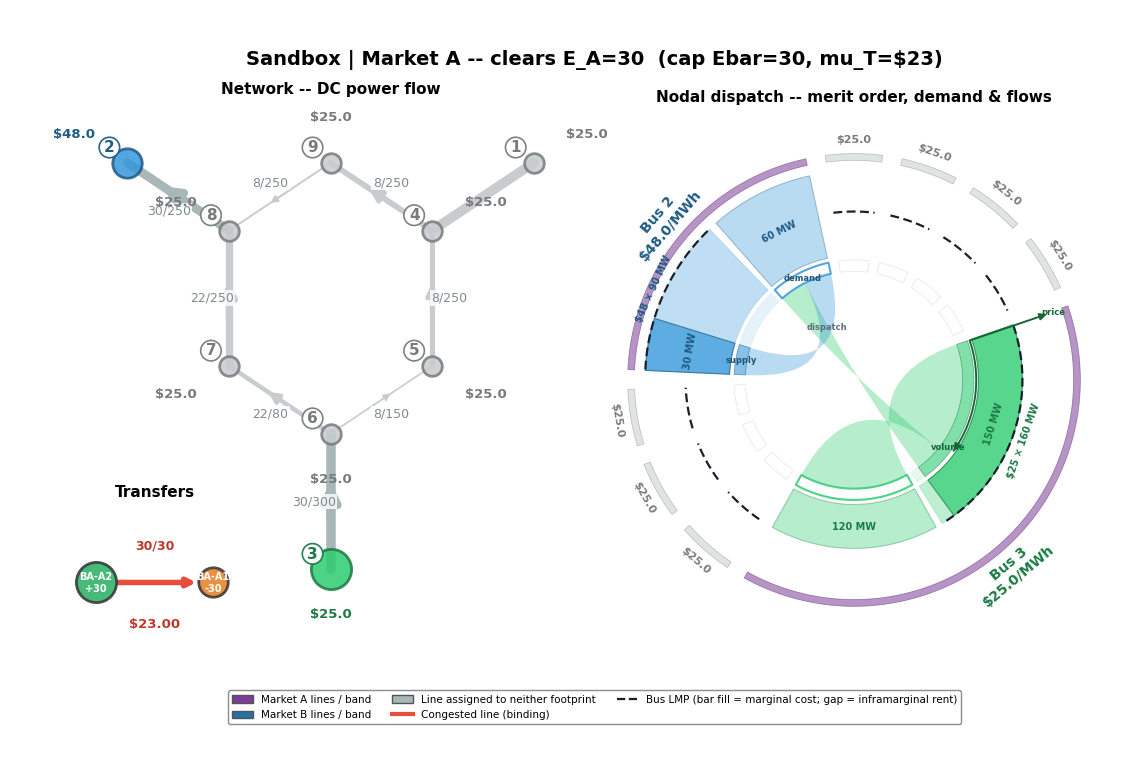

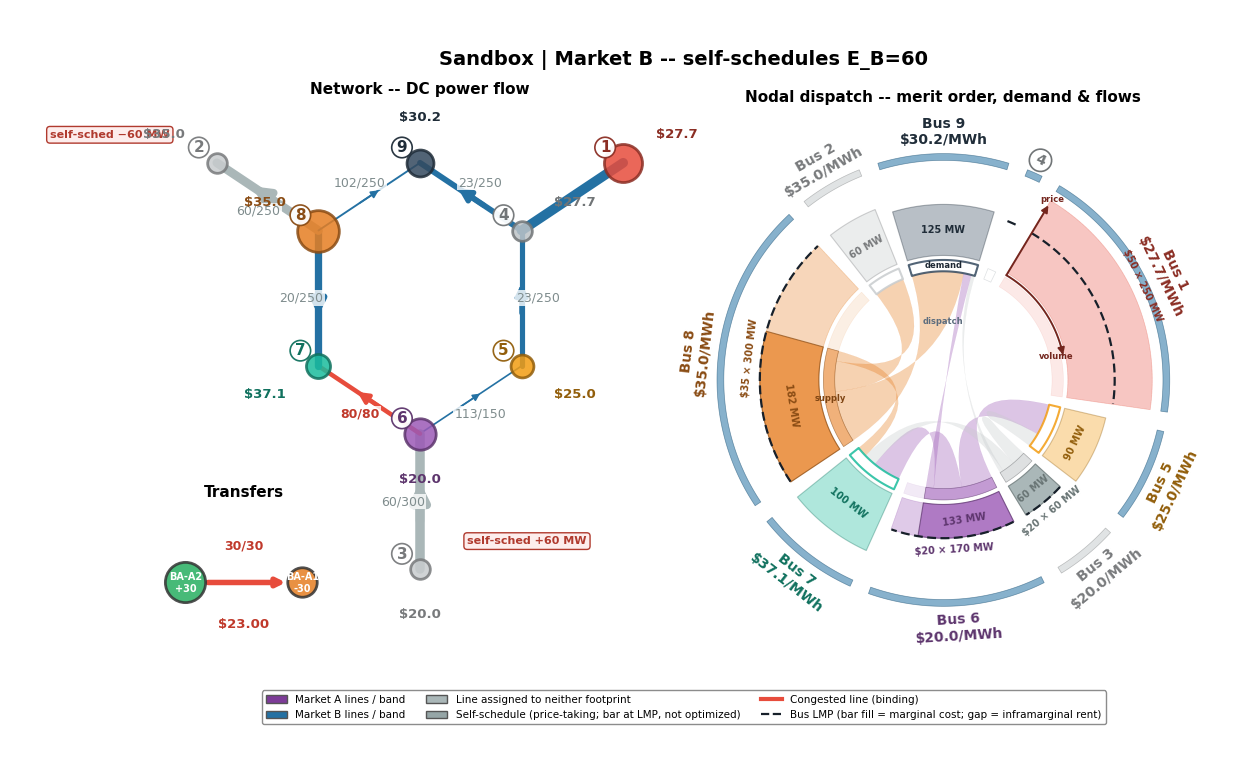

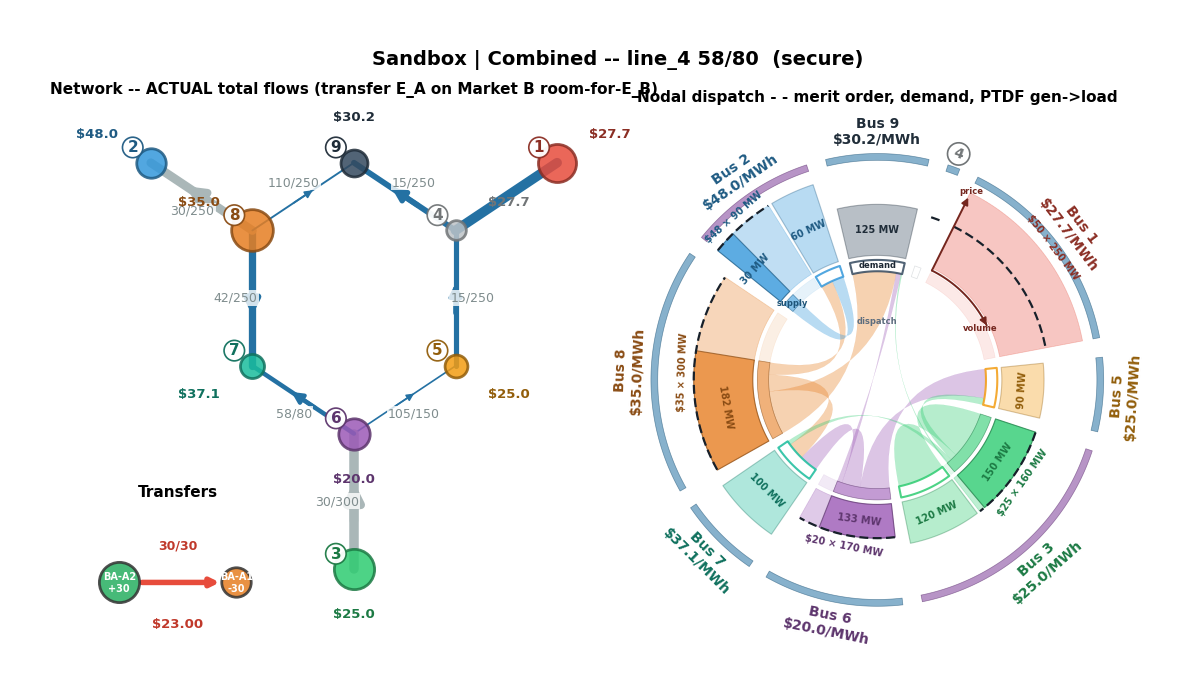

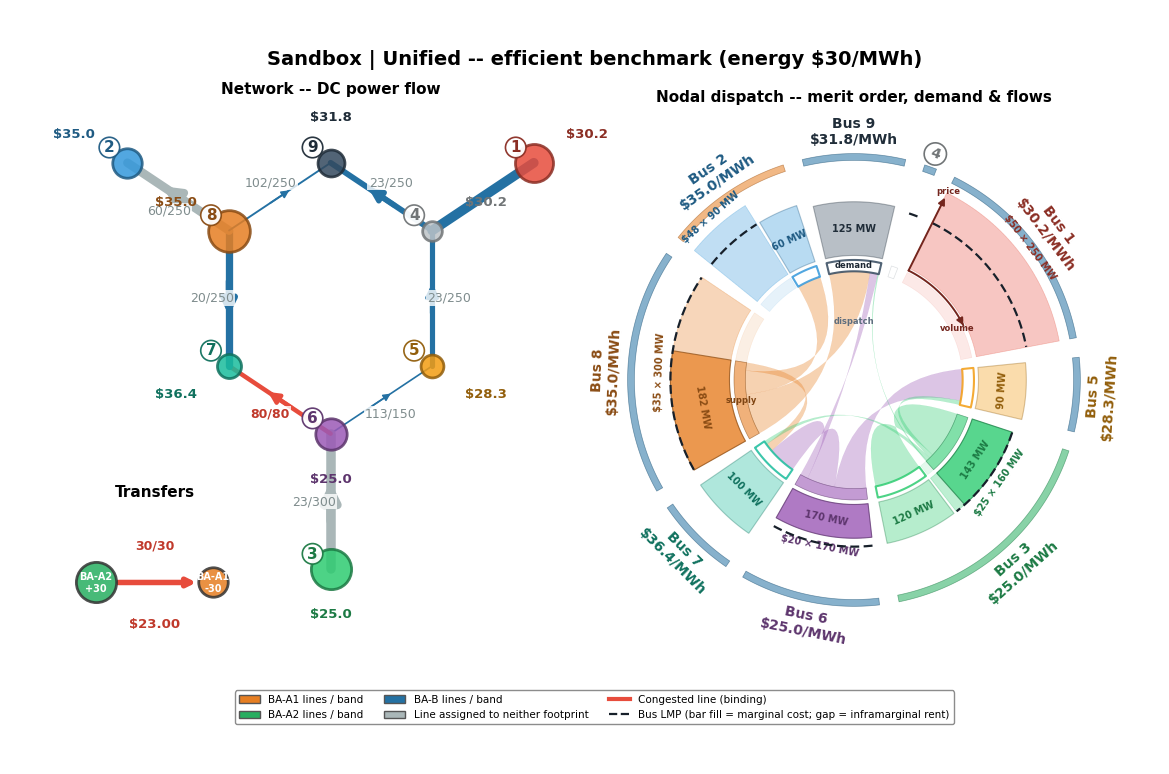

Transaction Pi = $795/h    Combined line_4 = 57.6/80  -- secure

In [21]:
# (4) The four network views for the configured case (day-ahead), with the transport inset.
sup_sb = {}
for _nm, _sp in gens_da.items():
    sup_sb.setdefault(_sp['bus'], []).append(_sp)
BUS_COLORS_SB = assign_bus_colors(pt_sb.buses, sup_sb, SB_LOADS_DA)
fp_mkt_sb = fpmod.make(pt_sb, MKT_SB, MKT_COLORS, manage={'Market B': BA_MANAGES['BA-B']}, tie_label='seam')
fp_ba_sb  = fpmod.make(pt_sb, BA_SB, BA_COLORS, manage=BA_MANAGES)
_tam = lambda b: sum(g.get('p_nom', 0.0) for g in sup_sb.get(b, [])) + SB_LOADS_DA.get(b, 0.0)
INS_L_SB = ('BA-A2', 'BA-A1'); INS_T_SB = {'BA-A2': _tam(SB_SRC), 'BA-A1': _tam(SB_SNK)}
INS_C_SB = {'BA-A2': BA_COLORS['BA-A2'], 'BA-A1': BA_COLORS['BA-A1']}
TIECAP_SB = max(SB_GENS_DA.get(SB_SRC, (0, 0))[1] - SB_LOADS_DA.get(SB_SRC, 0.0), SB_EBAR)
def _ins_sb(fig):
    figs.transfer_inset(fig.add_axes(figs.INSET_RECT), INS_L_SB, INS_T_SB,
                        {'BA-A2': +EA_sb, 'BA-A1': -EA_sb}, EA_sb, SB_EBAR, muT_sb, INS_C_SB, TIECAP_SB)

fA = figs.footprint_figure(net_sb, pt_sb, fp_mkt_sb, engA_sb, rA_sb, highlight='Market A',
                           bus_colors=BUS_COLORS_SB,
                           suptitle=f'Sandbox | Market A -- clears E_A={EA_sb:.0f}  (cap Ebar={SB_EBAR:.0f}, mu_T=${muT_sb:.0f})')
_ins_sb(fA); plt.show()
fB = figs.footprint_figure(net_sb, pt_sb, fp_mkt_sb, engB_sb, rB_sb, highlight='Market B',
                           bus_colors=BUS_COLORS_SB,
                           exo_sched=({SB_SRC: +SB_EB, SB_SNK: -SB_EB} if SB_EB > 1e-6 else None),
                           suptitle=f'Sandbox | Market B -- self-schedules E_B={SB_EB:.0f}')
_ins_sb(fB); plt.show()

# Combined: the actual total flows of Market A's transfer (E_A) + Market B's room-for-E_B dispatch.
p_sb = np.zeros(pt_sb.n_bus)
for r_ in (rA_sb, rB_sb):
    for b, mw in r_.gen_by_bus.items():  p_sb[pt_sb.bus_idx[b]] += mw
    for b, mw in r_.load_by_bus.items(): p_sb[pt_sb.bus_idx[b]] -= mw
f_sb = pt_sb.ptdf @ p_sb
over_sb = {l for l, x in zip(pt_sb.lines, f_sb) if abs(x) > pt_sb.s_nom[pt_sb.line_idx[l]] + 1e-6}
l4_sb = float(f_sb[pt_sb.line_idx['line_4']]); rate4_sb = pt_sb.s_nom[pt_sb.line_idx['line_4']]
host_sb = {b: (rA_sb.lmp[b] if b in MKT_SB['Market A'] else rB_sb.lmp[b]) for b in pt_sb.buses}
sup_d, dem_d = {}, {}
for _e, _r in ((engA_sb, rA_sb), (engB_sb, rB_sb)):
    _s, _d = to_supply_demand(_e, _r); sup_d.update(_s); dem_d.update(_d)
figC, _ = plot_combined_letter(
    net_sb, sup_d, dem_d, bus_colors=BUS_COLORS_SB, bus_lmps=host_sb,
    line_flows={l: float(x) for l, x in zip(pt_sb.lines, f_sb)},
    line_widths=susceptance_widths(pt_sb), line_colors=fp_mkt_sb.line_colors(pt_sb),
    constrained_lines=over_sb, flows=nodal_plot.compute_ptdf_flows(net_sb, sup_d, dem_d),
    lmp_line=True, bus_groups=fp_mkt_sb.groups(pt_sb), group_colors=dict(MKT_COLORS), show_group_labels=False,
    all_buses=pt_sb.buses, sector_order=RING_ORDER, bus_coords=COORDS, center_bus=CENTER_BUS,
    annotate_roles=True, axis_key=True,
    title_left='Network -- ACTUAL total flows (transfer E_A on Market B room-for-E_B)',
    suptitle=f'Sandbox | Combined -- line_4 {abs(l4_sb):.0f}/{rate4_sb:.0f}  ({"OVERLOAD" if over_sb else "secure"})')
_ins_sb(figC); plt.show()

fU = figs.footprint_figure(net_sb, pt_sb, fp_ba_sb, engU_sb, rU_sb, bus_colors=BUS_COLORS_SB,
                           suptitle=f'Sandbox | Unified -- efficient benchmark (energy ${rU_sb.energy_price:.0f}/MWh)')
_ins_sb(fU); plt.show()
print(f'Transaction Pi = ${Pi_sb:,.0f}/h    Combined line_4 = {abs(l4_sb):.1f}/{rate4_sb:.0f}'
      f'{"  -- OVERLOAD" if over_sb else "  -- secure"}')